# 材料带隙预测 - 本地运行版本

**整体流程：**
1. 导入库
2. 配置参数（在这里改 TEST_MODE、选模型）
3. 加载 matbench 数据
4. 定义特征提取函数
5. 定义 GNN 数据导出函数
6. 定义模型训练函数
7. 定义 SHAP 分析函数
8. **运行主流程**（从这里开始真正跑）

> 💡 **新手提示**：Cell 1~7 是「准备工具」，Cell 8 是「开始干活」。
> 每次打开 notebook，需要从头到尾按顺序跑一遍所有 cell。

In [1]:
# ==================== Cell 1：导入所有需要的库 ====================
import os
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split

from matbench.bench import MatbenchBenchmark
from matminer.featurizers.composition import ElementProperty, BandCenter
from matminer.featurizers.base import MultipleFeaturizer
from matminer.featurizers.structure import (
	DensityFeatures,
	GlobalSymmetryFeatures,
	StructuralHeterogeneity,
	ChemicalOrdering,
	Dimensionality,
)
from matminer.featurizers.structure.sites import SiteStatsFingerprint

import xgboost as xgb
import shap

print('✅ 所有库导入成功!')

~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ 所有库导入成功!


In [2]:
# ==================== Cell 2：配置参数 ====================
# ★ 这是你最常改的地方 ★
#
# 想快速测试代码是否能跑：TEST_MODE = True
# 想正式跑全量数据拿官方分数：TEST_MODE = False
#
# 想跑 XGBoost：MODELS_TO_RUN = ["xgb"]
# 想跑随机森林：MODELS_TO_RUN = ["rf"]
# 注意：每次只跑一个，不要同时放两个

MODELS_TO_RUN = ["xgb"]   # ← 改这里选模型

TASK_NAME  = "matbench_mp_gap"
TEST_MODE  = False     # ← 改这里切换模式
TEST_N     = 50      # 测试模式下每个 fold 用多少条数据
TEST_FOLDS = 1       # 测试模式下跑几个 fold
N_JOBS     = 6       # 并行数，Mac 建议先用 1

SEED     = 202
N_SPLITS = 5
TOPK     = 50

# 本地存储目录（会自动创建）
OUT_DIR        = Path(f"../matbench_outputs_v2_seed{SEED}") # replay: 新目录, 对照 run0709 结果 (特征缓存仍用 CACHE_DIR)
CACHE_DIR      = Path("../matbench_cache")
GNN_EXPORT_DIR = Path("../gnn_export")

OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
GNN_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

FEATURES_CACHE    = CACHE_DIR / "features_cache_structural.pkl"
FORCE_REFEATURIZE = False 
FORCE_RETRAIN     = False

print(f'✅ 配置完成')
print(f'   模型: {MODELS_TO_RUN}')
print(f'   TEST_MODE: {TEST_MODE}')
print(f'   输出目录: {OUT_DIR}')

✅ 配置完成
   模型: ['xgb']
   TEST_MODE: False
   输出目录: ../matbench_outputs_v2_seed202


In [3]:
# ==================== Cell 3：加载 matbench 数据 ====================
# 第一次运行会自动下载数据集，之后从本地缓存读取

mb         = MatbenchBenchmark(autoload=False)
task       = next(t for t in mb.tasks if t.dataset_name == TASK_NAME)
task.load()
target_col = task.metadata["target"]
print(f'✅ 任务加载成功: {TASK_NAME}')
print(f'   预测目标: {target_col}（带隙，单位 eV）')
print(f'   fold 列表: {list(task.folds)}')

2026-10-08 02:36:32 INFO     Initialized benchmark 'matbench_v0.1' with 13 tasks: 
['matbench_dielectric',
 'matbench_expt_gap',
 'matbench_expt_is_metal',
 'matbench_glass',
 'matbench_jdft2d',
 'matbench_log_gvrh',
 'matbench_log_kvrh',
 'matbench_mp_e_form',
 'matbench_mp_gap',
 'matbench_mp_is_metal',
 'matbench_perovskites',
 'matbench_phonons',
 'matbench_steels']
2026-10-08 02:36:32 INFO     Loading dataset 'matbench_mp_gap'...
2026-10-08 02:37:49 INFO     Dataset 'matbench_mp_gap loaded.
✅ 任务加载成功: matbench_mp_gap
   预测目标: gap pbe（带隙，单位 eV）
   fold 列表: [0, 1, 2, 3, 4]


In [4]:
# ==================== Cell 4：定义特征提取函数 ====================
# 把晶体结构（Structure 对象）转换成 XGBoost 能理解的数值特征

def _run_one_featurizer(featurizer, df, col, cache_path):
	"""运行单个特征提取器，优先读缓存"""
	if cache_path.exists() and not FORCE_REFEATURIZE:
		try:
			cached = pd.read_pickle(cache_path)
			if len(cached) == len(df):
				print(f'    ✅ 缓存命中: {cache_path.name}')
				return cached
			print(f'    ⚠️ 缓存长度不匹配，重新提取: {cache_path.name}')
		except Exception as e:
			print(f'    ⚠️ 缓存读取失败: {e}')

	print(f'    ⏳ 提取中: {cache_path.name}')
	result_df = featurizer.featurize_dataframe(df.copy(), col, ignore_errors=True)
	result_df = result_df.drop(columns=[col], errors='ignore')
	pd.to_pickle(result_df, cache_path)
	print(f'    💾 已缓存: {cache_path.name}')
	return result_df


def extract_features(structures, split_name: str) -> pd.DataFrame:
	"""提取全部特征（结构特征 + 化学式特征）"""
	print(f'\n  [特征提取] {split_name}')

	struct_df = pd.DataFrame({'structure': structures})
	comp_df   = pd.DataFrame({'comp': [s.composition for s in structures]})

	struct_featurizer_list = [
		('DensityFeatures',         DensityFeatures()),
		('GlobalSymmetryFeatures',  GlobalSymmetryFeatures()),
		('StructuralHeterogeneity', StructuralHeterogeneity()),
		('ChemicalOrdering',        ChemicalOrdering()),
		('Dimensionality',          Dimensionality()),
		('SiteStatsFingerprint',    SiteStatsFingerprint.from_preset('CrystalNNFingerprint_ops')),
	]
	comp_featurizer_list = [
		('ElementProperty', ElementProperty.from_preset('magpie')),
		('BandCenter',      BandCenter()),
	]

	all_parts = []
	print('  [1/2] 结构特征...')
	for name, fzer in struct_featurizer_list:
		fzer.set_n_jobs(N_JOBS)
		part = _run_one_featurizer(fzer, struct_df, 'structure', CACHE_DIR / f'{split_name}_{name}.pkl')
		all_parts.append(part)

	print('  [2/2] 化学式特征...')
	for name, fzer in comp_featurizer_list:
		fzer.set_n_jobs(N_JOBS)
		part = _run_one_featurizer(fzer, comp_df, 'comp', CACHE_DIR / f'{split_name}_{name}.pkl')
		all_parts.append(part)

	X = pd.concat(all_parts, axis=1)

	# 防止不同 featurizer 产生重名列
	X = X.loc[:, ~X.columns.duplicated()].copy()

	# 找出非数值列，比如 crystal_system 这种字符串类别
	non_numeric_cols = X.select_dtypes(exclude=[np.number, "bool"]).columns.tolist()

	if non_numeric_cols:
		print(f"  ⚠️ 发现非数值特征列，将进行 one-hot 编码: {non_numeric_cols}")

		# 把字符串/类别列转成 one-hot 数值列
		X = pd.get_dummies(X, columns=non_numeric_cols, dummy_na=True)

	# 把 bool 转成 0/1
	bool_cols = X.select_dtypes(include=["bool"]).columns
	if len(bool_cols) > 0:
		X[bool_cols] = X[bool_cols].astype(int)

	# 全部强制转成数值，转不了的变 NaN
	X = X.apply(pd.to_numeric, errors="coerce")

	# 处理 inf；NaN 保留，填充延后到 fold 内用训练集统计量执行 (fit on train)
	X = X.replace([np.inf, -np.inf], np.nan)

	print(f"  ✅ {split_name} 特征提取完成，总特征数: {X.shape[1]}")
	return X

In [5]:
# ==================== Cell 5：定义 GNN 数据导出函数 ====================
# 把每个 fold 的原始 Structure + 标签存成 pkl，以后 GNN 直接读

def export_fold_for_gnn(task_local, fold: int):
	"""导出单个 fold 的原始数据供 GNN 使用"""
	fold_dir = GNN_EXPORT_DIR / f'fold_{fold}'
	fold_dir.mkdir(parents=True, exist_ok=True)

	if (fold_dir / 'train_inputs.pkl').exists():
		print(f'  ✅ GNN 数据已存在，跳过: fold_{fold}')
		return

	print(f'  📦 导出 GNN 数据: fold_{fold}')
	train_df      = task_local.get_train_and_val_data(fold, as_type='df')
	train_df      = train_df.rename(columns=lambda x: x.strip())
	train_inputs  = train_df['structure'].tolist()
	train_outputs = train_df[target_col].tolist()

	test_df     = task_local.get_test_data(fold, as_type='df')
	test_df     = test_df.rename(columns=lambda x: x.strip())
	test_inputs = test_df['structure'].tolist()
	test_ids    = list(test_df.index)

	with open(fold_dir / 'train_inputs.pkl',  'wb') as f: pickle.dump(train_inputs,  f)
	with open(fold_dir / 'train_outputs.pkl', 'wb') as f: pickle.dump(train_outputs, f)
	with open(fold_dir / 'test_inputs.pkl',   'wb') as f: pickle.dump(test_inputs,   f)
	with open(fold_dir / 'test_ids.pkl',      'wb') as f: pickle.dump(test_ids,      f)

	print(f'  ✅ fold_{fold} 导出完成: 训练 {len(train_inputs)} 条 / 测试 {len(test_inputs)} 条')

print('✅ GNN 导出函数定义完成')

✅ GNN 导出函数定义完成


In [6]:
# ==================== Cell 6：定义模型训练函数 ====================

def make_model(model_name: str):
	if model_name == 'rf':
		return RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=6)
	elif model_name == 'xgb':
		return None
	else:
		raise ValueError(f'未知模型: {model_name}')


def xgb_train_and_predict(X_train, y_train, X_test, fold_idx: int):
	"""训练 XGBoost（带早停）并预测测试集"""
	X_tr, X_val, y_tr, y_val = train_test_split(
		X_train, y_train, test_size=0.2, random_state=SEED, shuffle=True
	)
	dtr   = xgb.DMatrix(X_tr,   label=y_tr)
	dval  = xgb.DMatrix(X_val,  label=y_val)
	dtest = xgb.DMatrix(X_test)

	params = {
		'objective':        'reg:squarederror',
		'eval_metric':      'mae',
		'eta':              0.03,
		'max_depth':        6,
		'min_child_weight': 5,
		'subsample':        0.8,
		'colsample_bytree': 0.8,
		'lambda':           1.0,
		'alpha':            1e-3,
		'tree_method':      'hist',
		'seed':             SEED,
	}

	evals_result = {}
	print(f'  [XGBoost Fold {fold_idx+1}] 开始训练...')

	num_boost_round       = 500  if TEST_MODE else 8000
	early_stopping_rounds = 50   if TEST_MODE else 200

	booster = xgb.train(
		params=params, dtrain=dtr,
		num_boost_round=num_boost_round,
		evals=[(dval, 'validation')],
		evals_result=evals_result,
		early_stopping_rounds=early_stopping_rounds,
		verbose_eval=50,
	)

	best_it    = booster.best_iteration
	best_score = booster.best_score
	print(f'  [XGBoost Fold {fold_idx+1}] 完成: 最优轮数={best_it}, 验证MAE={best_score:.4f} eV')

	try:
		y_pred = booster.predict(dtest, iteration_range=(0, best_it + 1))
	except TypeError:
		y_pred = booster.predict(dtest, ntree_limit=best_it + 1)

	# 保存训练曲线
	if 'validation' in evals_result and 'mae' in evals_result['validation']:
		val_mae_list = evals_result['validation']['mae']
		epochs = list(range(1, len(val_mae_list) + 1))
		plt.figure(figsize=(10, 6))
		plt.plot(epochs, val_mae_list, label='验证集 MAE', color='blue')
		plt.axvline(x=best_it+1, color='red', linestyle='--',
					label=f'最优轮数: {best_it} (MAE={best_score:.4f})')
		plt.xlabel('训练轮数'); plt.ylabel('MAE (eV)')
		plt.title(f'XGBoost 训练曲线 - fold {fold_idx}')
		plt.legend(); plt.grid(True, alpha=0.3)
		curve_path = OUT_DIR / f'xgb_mae_curve_fold_{fold_idx}.png'
		plt.savefig(curve_path, dpi=150, bbox_inches='tight')
		plt.show()
		print(f'  → 训练曲线已保存: {curve_path}')

	return booster, y_pred

print('✅ 模型训练函数定义完成')

✅ 模型训练函数定义完成


In [7]:
# ==================== Cell 7：定义 SHAP 和特征重要性函数 ====================

def run_shap_analysis(booster_or_model, X_train, feature_names, fold_idx: int, model_name: str):
	"""计算 SHAP 值，保存蜂群图和重要性条形图"""
	print(f'\n  [SHAP 分析] Fold {fold_idx+1}...')

	n_shap  = min(3000, len(X_train))
	rng     = np.random.RandomState(SEED)
	idx     = rng.choice(len(X_train), n_shap, replace=False)
	X_shap  = X_train.iloc[idx] if hasattr(X_train, 'iloc') else X_train[idx]
	explainer   = shap.TreeExplainer(booster_or_model)
	shap_values = explainer.shap_values(X_shap, check_additivity=False)
	
	# 蜂群图
	plt.figure(figsize=(12, 8))
	shap.summary_plot(shap_values, X_shap, feature_names=feature_names, show=False, max_display=20)
	plt.title(f'SHAP 蜂群图 - {model_name} fold {fold_idx}')
	plt.tight_layout()
	beeswarm_path = OUT_DIR / f'shap_beeswarm_{model_name}_fold_{fold_idx}.png'
	plt.savefig(beeswarm_path, dpi=150, bbox_inches='tight')
	plt.show()
	print(f'  → SHAP 蜂群图已保存: {beeswarm_path}')

	# 重要性条形图
	plt.figure(figsize=(12, 8))
	shap.summary_plot(shap_values, X_shap, feature_names=feature_names,
					  plot_type='bar', show=False, max_display=20)
	plt.title(f'SHAP 特征重要性 - {model_name} fold {fold_idx}')
	plt.tight_layout()
	bar_path = OUT_DIR / f'shap_importance_{model_name}_fold_{fold_idx}.png'
	plt.savefig(bar_path, dpi=150, bbox_inches='tight')
	plt.show()
	print(f'  → SHAP 重要性图已保存: {bar_path}')

	np.save(OUT_DIR / f'shap_values_{model_name}_fold_{fold_idx}.npy', shap_values)
	with open(OUT_DIR / f'shap_feature_names_{model_name}.json', 'w', encoding='utf-8') as f:
		json.dump(list(feature_names), f, ensure_ascii=False)


def plot_feature_importance(booster_or_model, feature_names, fold_idx: int, model_name: str):
	"""画模型内置特征重要性图"""
	print(f'\n  [特征重要性] Fold {fold_idx+1}...')

	if model_name == 'xgb':
		importance_dict = booster_or_model.get_score(importance_type='gain')
		importances = np.array([importance_dict.get(f'f{i}', 0) for i in range(len(feature_names))])
	else:
		importances = booster_or_model.feature_importances_

	top_k   = 20
	indices = np.argsort(importances)[::-1][:top_k]

	plt.figure(figsize=(12, 8))
	plt.barh([feature_names[i] for i in indices][::-1], importances[indices][::-1], color='steelblue')
	plt.xlabel('特征重要性 (Gain)')
	plt.title(f'Top {top_k} 特征重要性 - {model_name} fold {fold_idx}')
	plt.tight_layout()
	fig_path = OUT_DIR / f'feature_importance_{model_name}_fold_{fold_idx}.png'
	plt.savefig(fig_path, dpi=150, bbox_inches='tight')
	plt.show()
	print(f'  → 特征重要性图已保存: {fig_path}')

print('✅ SHAP 和特征重要性函数定义完成')

✅ SHAP 和特征重要性函数定义完成


In [8]:
# ==================== Cell 8：定义主函数 ====================

def run_one_model(model_name: str):
	"""完整运行一个模型的所有 fold"""
	predictions_dir = OUT_DIR / f'predictions_{model_name}'
	predictions_dir.mkdir(parents=True, exist_ok=True)

	mb_local   = MatbenchBenchmark(autoload=False)
	task_local = next(t for t in mb_local.tasks if t.dataset_name == TASK_NAME)
	task_local.load()

	folds_to_run = list(task_local.folds)
	if TEST_MODE:
		folds_to_run = folds_to_run[:TEST_FOLDS]
		print(f'⚠️  TEST_MODE=True：只跑前 {len(folds_to_run)} 个 fold，每个取前 {TEST_N} 条')

	for fold_idx, fold in enumerate(folds_to_run):
		print(f'\n{"="*60}')
		print(f'[{model_name}] Fold {fold_idx+1}/{len(folds_to_run)}')
		print(f'{"="*60}')

		pred_suffix = f'test{TEST_N}_fold_{fold}' if TEST_MODE else f'fold_{fold}'
		pred_file   = predictions_dir / f'pred_{pred_suffix}.npy'
		if pred_file.exists() and not FORCE_RETRAIN:
			print(f'  预测文件已存在，跳过: {pred_file}')
			y_pred = np.load(pred_file)
			if not TEST_MODE:
				task_local.record(fold, y_pred)
			continue

		# 获取数据
		train_df = task_local.get_train_and_val_data(fold, as_type='df')
		test_df  = task_local.get_test_data(fold, as_type='df')
		train_df = train_df.rename(columns=lambda x: x.strip())
		test_df  = test_df.rename(columns=lambda x: x.strip())

		if TEST_MODE:
			train_df = train_df.iloc[:TEST_N].copy()
			test_df  = test_df.iloc[:TEST_N].copy()

		X_train_raw = train_df['structure'].tolist()
		y_train     = train_df[target_col].to_numpy()
		X_test_raw  = test_df['structure'].tolist()
		print(f'  训练集: {len(X_train_raw)} 条，测试集: {len(X_test_raw)} 条')

		# 导出 GNN 数据（只在全量模式下）
		if not TEST_MODE:
			export_fold_for_gnn(task_local, fold)

		# 提取特征
		cache_prefix = f"test{TEST_N}_fold_{fold}" if TEST_MODE else f"fold_{fold}"

		print(f"\n  提取训练集特征...")
		X_train = extract_features(X_train_raw, split_name=f"{cache_prefix}_train")

		print(f"\n  提取测试集特征...")
		X_test = extract_features(X_test_raw, split_name=f"{cache_prefix}_test")

		# 关键：保证 train/test 的 one-hot 特征列完全一致
		X_train, X_test = X_train.align(X_test, join="outer", axis=1, fill_value=0)

		# 填充: 统计量只从训练集来 (fit on train, transform on test)
		col_means = X_train.mean(numeric_only=True)
		X_train   = X_train.fillna(col_means).fillna(0)
		X_test    = X_test.fillna(col_means).fillna(0)

		feature_names = list(X_train.columns)   # 保存特征名，SHAP 图需要用

		# 训练和预测
		if model_name == 'xgb':
			booster, y_pred = xgb_train_and_predict(X_train, y_train, X_test, fold_idx)
			run_shap_analysis(booster, X_train, feature_names, fold_idx, model_name)
			plot_feature_importance(booster, feature_names, fold_idx, model_name)
		else:
			model = make_model(model_name)
			model.fit(X_train, y_train)
			y_pred = model.predict(X_test)
			if fold_idx == 0:   # RF 的 SHAP 只需一份，fold 0 已有，后续 fold 全跳过
				run_shap_analysis(model, X_train, feature_names, fold_idx, model_name)
				plot_feature_importance(model, feature_names, fold_idx, model_name)

		np.save(predictions_dir / f'pred_raw_{pred_suffix}.npy', y_pred)  # [replay] 新增: clip 前的原始预测
		y_pred = np.maximum(y_pred, 0)  # 物理约束: 带隙非负
		np.save(pred_file, y_pred)
		print(f'\n  → 预测结果已保存: {pred_file}')

		if not TEST_MODE:
			task_local.record(fold, y_pred)
			print(f'  → 已提交 fold {fold} 给 matbench')

	# 计算分数
	if TEST_MODE:
		scores = {'说明': 'TEST_MODE=True，不是官方分数', '模型': model_name}
		print('\n⚠️  TEST_MODE=True，跳过官方评分')
	else:
		scores = task_local.scores
		print(f'\n✅ 官方分数: {scores}')

	metrics_path = OUT_DIR / f'scores_{model_name}{"_testmode" if TEST_MODE else ""}.txt'
	with metrics_path.open('w', encoding='utf-8') as f:
		f.write(f'任务: {TASK_NAME}\n模型: {model_name}\n\n分数:\n{str(scores)}\n')
	print(f'✅ 分数已保存: {metrics_path}')
	return scores

print('✅ 主函数定义完成')

✅ 主函数定义完成



=== 开始跑模型: xgb ===
2026-10-08 02:37:49 INFO     Initialized benchmark 'matbench_v0.1' with 13 tasks: 
['matbench_dielectric',
 'matbench_expt_gap',
 'matbench_expt_is_metal',
 'matbench_glass',
 'matbench_jdft2d',
 'matbench_log_gvrh',
 'matbench_log_kvrh',
 'matbench_mp_e_form',
 'matbench_mp_gap',
 'matbench_mp_is_metal',
 'matbench_perovskites',
 'matbench_phonons',
 'matbench_steels']
2026-10-08 02:37:49 INFO     Loading dataset 'matbench_mp_gap'...
2026-10-08 02:39:11 INFO     Dataset 'matbench_mp_gap loaded.

[xgb] Fold 1/5
  训练集: 84890 条，测试集: 21223 条
  ✅ GNN 数据已存在，跳过: fold_0

  提取训练集特征...

  [特征提取] fold_0_train


~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/featurizers/composition/element.py:216: UserWarning: BandCenter(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by th

  [1/2] 结构特征...
    ✅ 缓存命中: fold_0_train_DensityFeatures.pkl
    ✅ 缓存命中: fold_0_train_GlobalSymmetryFeatures.pkl
    ✅ 缓存命中: fold_0_train_StructuralHeterogeneity.pkl
    ✅ 缓存命中: fold_0_train_ChemicalOrdering.pkl
    ✅ 缓存命中: fold_0_train_Dimensionality.pkl
    ✅ 缓存命中: fold_0_train_SiteStatsFingerprint.pkl
  [2/2] 化学式特征...
    ✅ 缓存命中: fold_0_train_ElementProperty.pkl
    ✅ 缓存命中: fold_0_train_BandCenter.pkl
  ⚠️ 发现非数值特征列，将进行 one-hot 编码: ['crystal_system']
  ✅ fold_0_train 特征提取完成，总特征数: 283

  提取测试集特征...

  [特征提取] fold_0_test


~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/featurizers/composition/element.py:216: UserWarning: BandCenter(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by th

  [1/2] 结构特征...
    ✅ 缓存命中: fold_0_test_DensityFeatures.pkl
    ✅ 缓存命中: fold_0_test_GlobalSymmetryFeatures.pkl
    ✅ 缓存命中: fold_0_test_StructuralHeterogeneity.pkl
    ✅ 缓存命中: fold_0_test_ChemicalOrdering.pkl
    ✅ 缓存命中: fold_0_test_Dimensionality.pkl
    ✅ 缓存命中: fold_0_test_SiteStatsFingerprint.pkl
  [2/2] 化学式特征...
    ✅ 缓存命中: fold_0_test_ElementProperty.pkl
    ✅ 缓存命中: fold_0_test_BandCenter.pkl
  ⚠️ 发现非数值特征列，将进行 one-hot 编码: ['crystal_system']
  ✅ fold_0_test 特征提取完成，总特征数: 283
  [XGBoost Fold 1] 开始训练...
[0]	validation-mae:1.30910
[50]	validation-mae:0.71409
[100]	validation-mae:0.54958
[150]	validation-mae:0.49167
[200]	validation-mae:0.46623
[250]	validation-mae:0.44577
[300]	validation-mae:0.43244
[350]	validation-mae:0.42088
[400]	validation-mae:0.41219
[450]	validation-mae:0.40499
[500]	validation-mae:0.39902
[550]	validation-mae:0.39386
[600]	validation-mae:0.38951
[650]	validation-mae:0.38435
[700]	validation-mae:0.38039
[750]	validation-mae:0.37685
[800]	validation-mae:0.37312
[

/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 35757 (\N{CJK UNIFIED IDEOGRAPH-8BAD}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 32451 (\N{CJK UNIFIED IDEOGRAPH-7EC3}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.

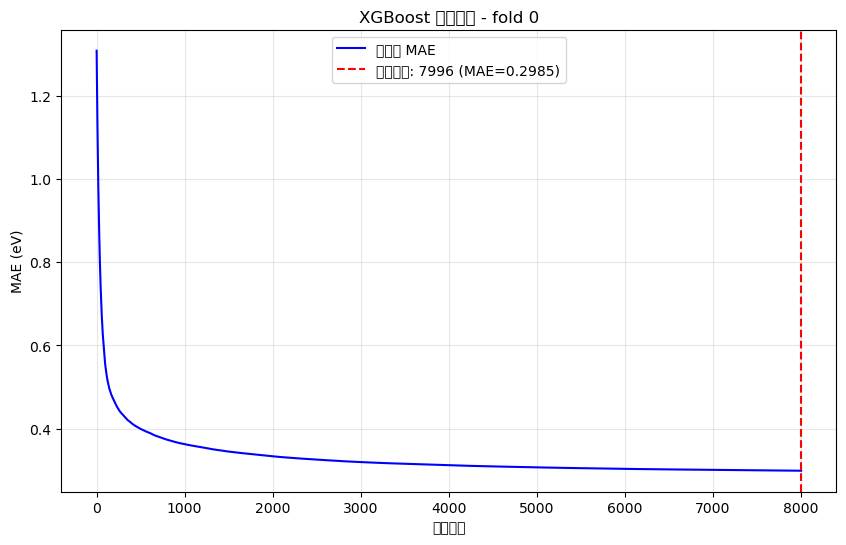

  → 训练曲线已保存: ../matbench_outputs_v2_seed202/xgb_mae_curve_fold_0.png

  [SHAP 分析] Fold 1...


/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:18: UserWarning: Glyph 34562 (\N{CJK UNIFIED IDEOGRAPH-8702}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:18: UserWarning: Glyph 32676 (\N{CJK UNIFIED IDEOGRAPH-7FA4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:18: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:20: UserWarning: Glyph 34562 (\N{CJK UNIFIED IDEOGRAPH-8702}) missing from font(s) DejaVu Sans.
  plt.savefig(beeswarm_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:20: UserWarning: Glyph 32676 (\N{CJK UNIFIED IDEOGRAPH-7FA4}) missing from font(s) DejaVu Sans.
  p

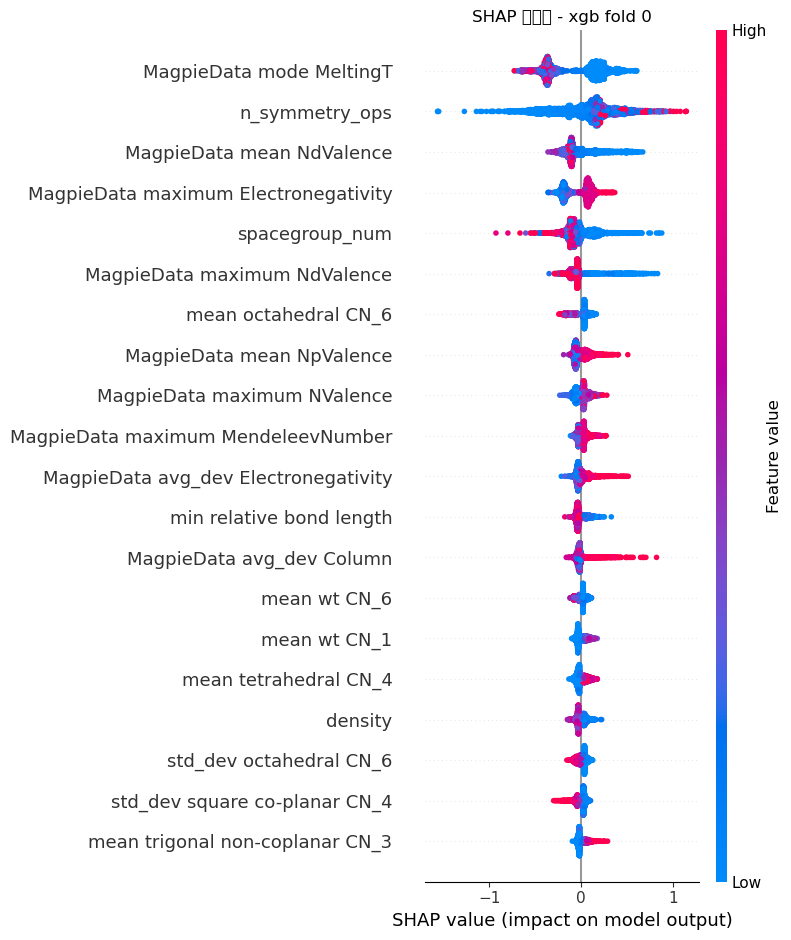

/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 37325 (\N{CJK UNIFIED IDEOGRAPH-91CD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 35201 (\N{CJK UNIFIED IDEOGRAPH-8981}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4

  → SHAP 蜂群图已保存: ../matbench_outputs_v2_seed202/shap_beeswarm_xgb_fold_0.png


~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 37325 (\N{CJK UNIFIED IDEOGRAPH-91CD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 35201 (\N{CJK UNIFIED IDEOGRAPH-8981}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: G

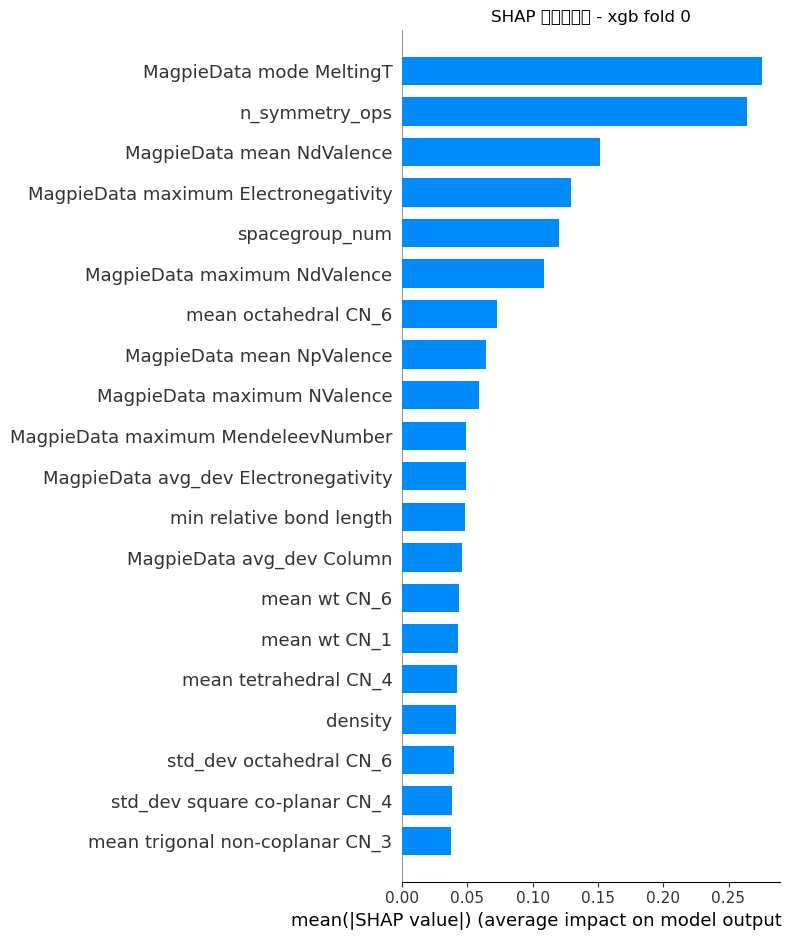

  → SHAP 重要性图已保存: ../matbench_outputs_v2_seed202/shap_importance_xgb_fold_0.png

  [特征重要性] Fold 1...


/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 37325 (\N{CJK UNIFIED IDEOGRAPH-91CD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 35201 (\N{CJK UNIFIED IDEOGRAPH-8981}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4

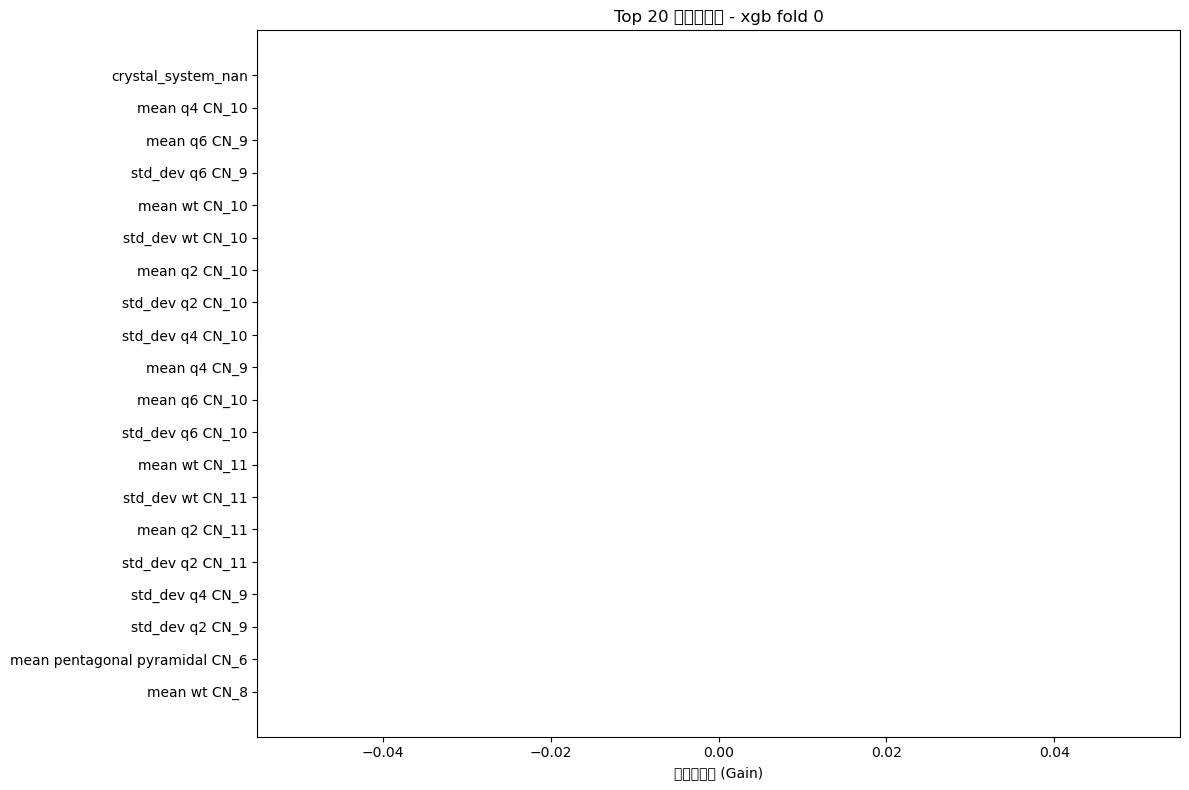

  → 特征重要性图已保存: ../matbench_outputs_v2_seed202/feature_importance_xgb_fold_0.png

  → 预测结果已保存: ../matbench_outputs_v2_seed202/predictions_xgb/pred_fold_0.npy
2026-10-08 02:41:06 INFO     Recorded fold matbench_mp_gap-0 successfully.
  → 已提交 fold 0 给 matbench

[xgb] Fold 2/5
  训练集: 84890 条，测试集: 21223 条
  ✅ GNN 数据已存在，跳过: fold_1

  提取训练集特征...

  [特征提取] fold_1_train


~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/featurizers/composition/element.py:216: UserWarning: BandCenter(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by th

  [1/2] 结构特征...
    ✅ 缓存命中: fold_1_train_DensityFeatures.pkl
    ✅ 缓存命中: fold_1_train_GlobalSymmetryFeatures.pkl
    ✅ 缓存命中: fold_1_train_StructuralHeterogeneity.pkl
    ✅ 缓存命中: fold_1_train_ChemicalOrdering.pkl
    ✅ 缓存命中: fold_1_train_Dimensionality.pkl
    ✅ 缓存命中: fold_1_train_SiteStatsFingerprint.pkl
  [2/2] 化学式特征...
    ✅ 缓存命中: fold_1_train_ElementProperty.pkl
    ✅ 缓存命中: fold_1_train_BandCenter.pkl
  ⚠️ 发现非数值特征列，将进行 one-hot 编码: ['crystal_system']
  ✅ fold_1_train 特征提取完成，总特征数: 283

  提取测试集特征...

  [特征提取] fold_1_test


~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/featurizers/composition/element.py:216: UserWarning: BandCenter(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by th

  [1/2] 结构特征...
    ✅ 缓存命中: fold_1_test_DensityFeatures.pkl
    ✅ 缓存命中: fold_1_test_GlobalSymmetryFeatures.pkl
    ✅ 缓存命中: fold_1_test_StructuralHeterogeneity.pkl
    ✅ 缓存命中: fold_1_test_ChemicalOrdering.pkl
    ✅ 缓存命中: fold_1_test_Dimensionality.pkl
    ✅ 缓存命中: fold_1_test_SiteStatsFingerprint.pkl
  [2/2] 化学式特征...
    ✅ 缓存命中: fold_1_test_ElementProperty.pkl
    ✅ 缓存命中: fold_1_test_BandCenter.pkl
  ⚠️ 发现非数值特征列，将进行 one-hot 编码: ['crystal_system']
  ✅ fold_1_test 特征提取完成，总特征数: 283
  [XGBoost Fold 2] 开始训练...
[0]	validation-mae:1.31997
[50]	validation-mae:0.72313
[100]	validation-mae:0.55597
[150]	validation-mae:0.49719
[200]	validation-mae:0.46880
[250]	validation-mae:0.44940
[300]	validation-mae:0.43530
[350]	validation-mae:0.42501
[400]	validation-mae:0.41599
[450]	validation-mae:0.40802
[500]	validation-mae:0.40235
[550]	validation-mae:0.39696
[600]	validation-mae:0.39203
[650]	validation-mae:0.38737
[700]	validation-mae:0.38330
[750]	validation-mae:0.37988
[800]	validation-mae:0.37641
[

/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 35757 (\N{CJK UNIFIED IDEOGRAPH-8BAD}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 32451 (\N{CJK UNIFIED IDEOGRAPH-7EC3}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.

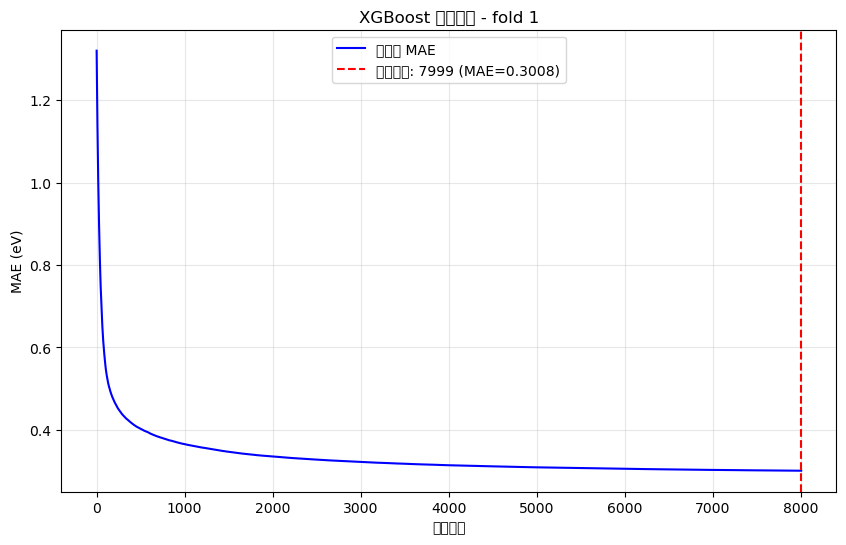

  → 训练曲线已保存: ../matbench_outputs_v2_seed202/xgb_mae_curve_fold_1.png

  [SHAP 分析] Fold 2...


/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:18: UserWarning: Glyph 34562 (\N{CJK UNIFIED IDEOGRAPH-8702}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:18: UserWarning: Glyph 32676 (\N{CJK UNIFIED IDEOGRAPH-7FA4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:18: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:20: UserWarning: Glyph 34562 (\N{CJK UNIFIED IDEOGRAPH-8702}) missing from font(s) DejaVu Sans.
  plt.savefig(beeswarm_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:20: UserWarning: Glyph 32676 (\N{CJK UNIFIED IDEOGRAPH-7FA4}) missing from font(s) DejaVu Sans.
  p

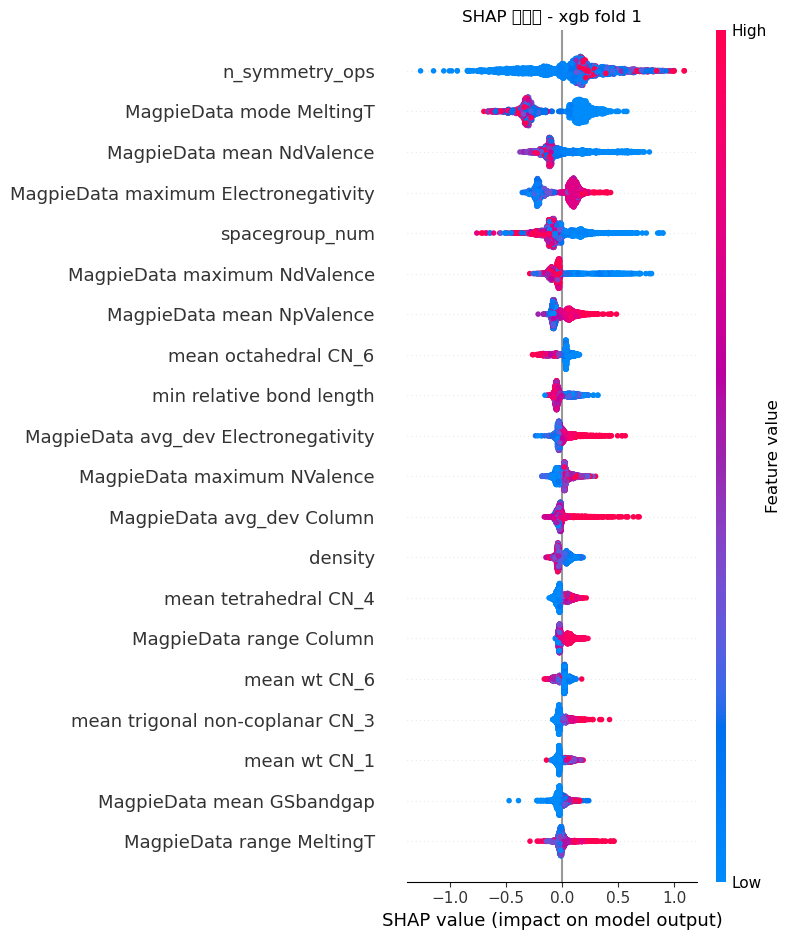

/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 37325 (\N{CJK UNIFIED IDEOGRAPH-91CD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 35201 (\N{CJK UNIFIED IDEOGRAPH-8981}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4

  → SHAP 蜂群图已保存: ../matbench_outputs_v2_seed202/shap_beeswarm_xgb_fold_1.png


~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 37325 (\N{CJK UNIFIED IDEOGRAPH-91CD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 35201 (\N{CJK UNIFIED IDEOGRAPH-8981}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: G

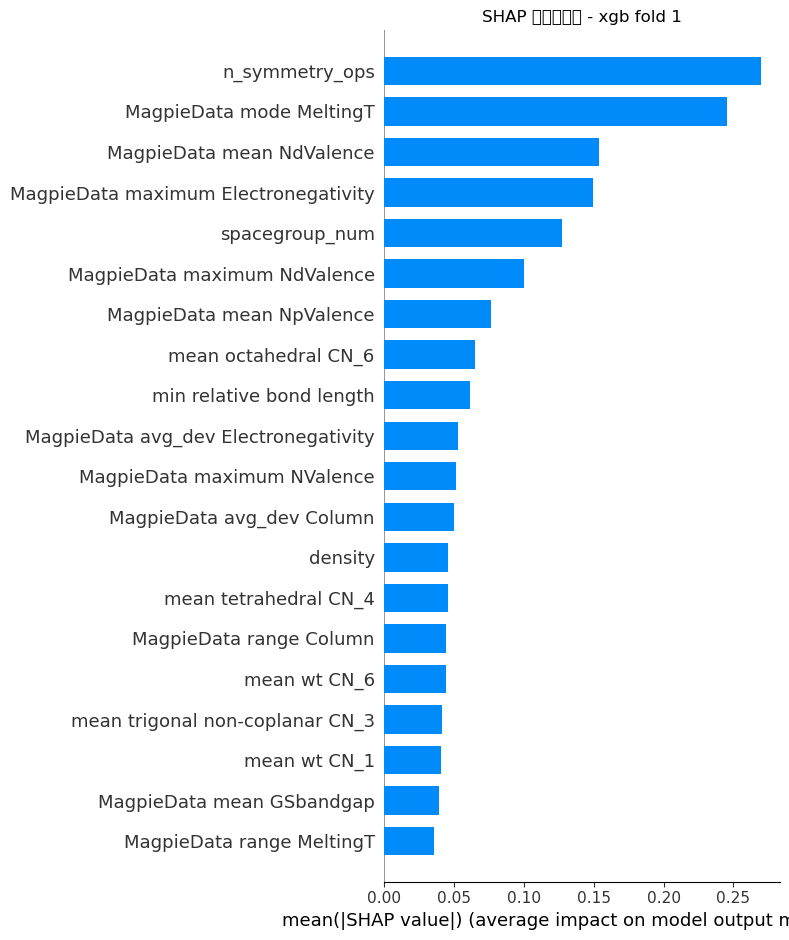

  → SHAP 重要性图已保存: ../matbench_outputs_v2_seed202/shap_importance_xgb_fold_1.png


/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 37325 (\N{CJK UNIFIED IDEOGRAPH-91CD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 35201 (\N{CJK UNIFIED IDEOGRAPH-8981}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4


  [特征重要性] Fold 2...


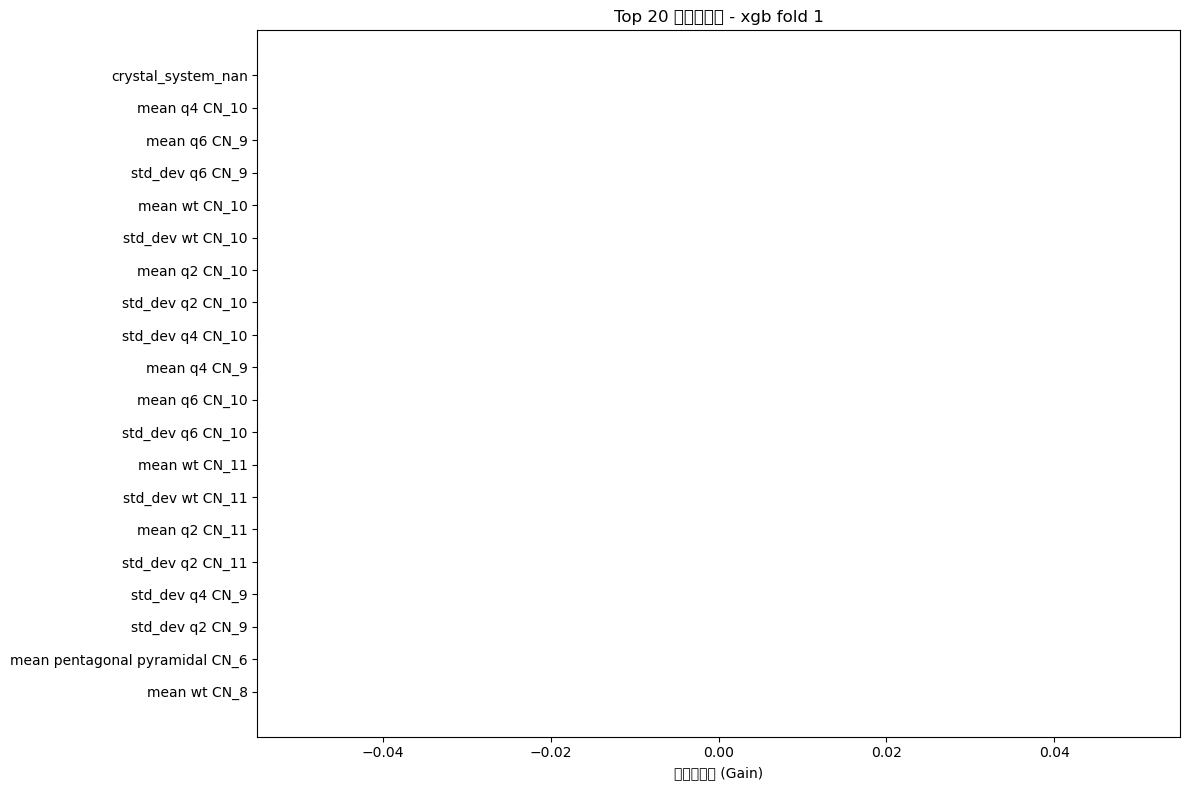

  → 特征重要性图已保存: ../matbench_outputs_v2_seed202/feature_importance_xgb_fold_1.png

  → 预测结果已保存: ../matbench_outputs_v2_seed202/predictions_xgb/pred_fold_1.npy
2026-10-08 02:42:55 INFO     Recorded fold matbench_mp_gap-1 successfully.
  → 已提交 fold 1 给 matbench

[xgb] Fold 3/5
  训练集: 84890 条，测试集: 21223 条
  ✅ GNN 数据已存在，跳过: fold_2

  提取训练集特征...

  [特征提取] fold_2_train


~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/featurizers/composition/element.py:216: UserWarning: BandCenter(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by th

  [1/2] 结构特征...
    ✅ 缓存命中: fold_2_train_DensityFeatures.pkl
    ✅ 缓存命中: fold_2_train_GlobalSymmetryFeatures.pkl
    ✅ 缓存命中: fold_2_train_StructuralHeterogeneity.pkl
    ✅ 缓存命中: fold_2_train_ChemicalOrdering.pkl
    ✅ 缓存命中: fold_2_train_Dimensionality.pkl
    ✅ 缓存命中: fold_2_train_SiteStatsFingerprint.pkl
  [2/2] 化学式特征...
    ✅ 缓存命中: fold_2_train_ElementProperty.pkl
    ✅ 缓存命中: fold_2_train_BandCenter.pkl
  ⚠️ 发现非数值特征列，将进行 one-hot 编码: ['crystal_system']
  ✅ fold_2_train 特征提取完成，总特征数: 283

  提取测试集特征...

  [特征提取] fold_2_test


~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/featurizers/composition/element.py:216: UserWarning: BandCenter(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by th

  [1/2] 结构特征...
    ✅ 缓存命中: fold_2_test_DensityFeatures.pkl
    ✅ 缓存命中: fold_2_test_GlobalSymmetryFeatures.pkl
    ✅ 缓存命中: fold_2_test_StructuralHeterogeneity.pkl
    ✅ 缓存命中: fold_2_test_ChemicalOrdering.pkl
    ✅ 缓存命中: fold_2_test_Dimensionality.pkl
    ✅ 缓存命中: fold_2_test_SiteStatsFingerprint.pkl
  [2/2] 化学式特征...
    ✅ 缓存命中: fold_2_test_ElementProperty.pkl
    ✅ 缓存命中: fold_2_test_BandCenter.pkl
  ⚠️ 发现非数值特征列，将进行 one-hot 编码: ['crystal_system']
  ✅ fold_2_test 特征提取完成，总特征数: 283
  [XGBoost Fold 3] 开始训练...
[0]	validation-mae:1.29199
[50]	validation-mae:0.70146
[100]	validation-mae:0.53558
[150]	validation-mae:0.48189
[200]	validation-mae:0.45604
[250]	validation-mae:0.43773
[300]	validation-mae:0.42432
[350]	validation-mae:0.41487
[400]	validation-mae:0.40721
[450]	validation-mae:0.40045
[500]	validation-mae:0.39422
[550]	validation-mae:0.38924
[600]	validation-mae:0.38481
[650]	validation-mae:0.38072
[700]	validation-mae:0.37697
[750]	validation-mae:0.37323
[800]	validation-mae:0.36973
[

/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 35757 (\N{CJK UNIFIED IDEOGRAPH-8BAD}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 32451 (\N{CJK UNIFIED IDEOGRAPH-7EC3}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.

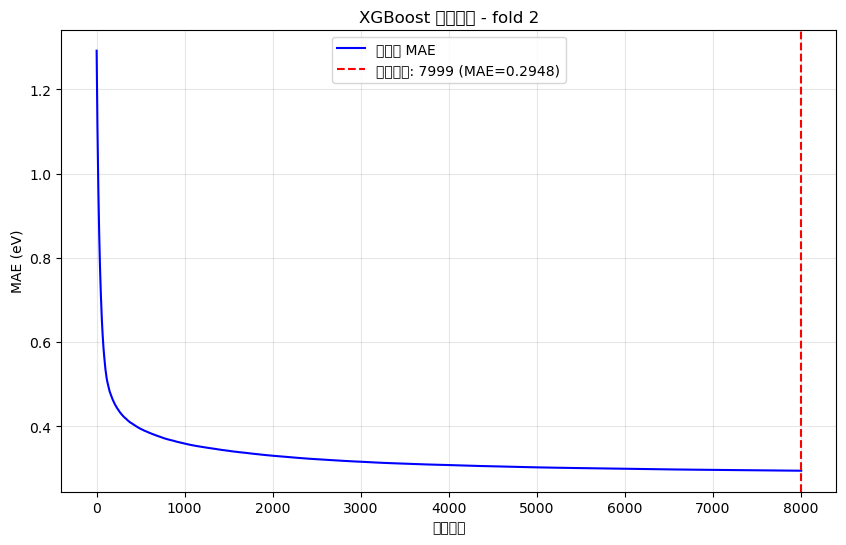

  → 训练曲线已保存: ../matbench_outputs_v2_seed202/xgb_mae_curve_fold_2.png

  [SHAP 分析] Fold 3...


/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:18: UserWarning: Glyph 34562 (\N{CJK UNIFIED IDEOGRAPH-8702}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:18: UserWarning: Glyph 32676 (\N{CJK UNIFIED IDEOGRAPH-7FA4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:18: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:20: UserWarning: Glyph 34562 (\N{CJK UNIFIED IDEOGRAPH-8702}) missing from font(s) DejaVu Sans.
  plt.savefig(beeswarm_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:20: UserWarning: Glyph 32676 (\N{CJK UNIFIED IDEOGRAPH-7FA4}) missing from font(s) DejaVu Sans.
  p

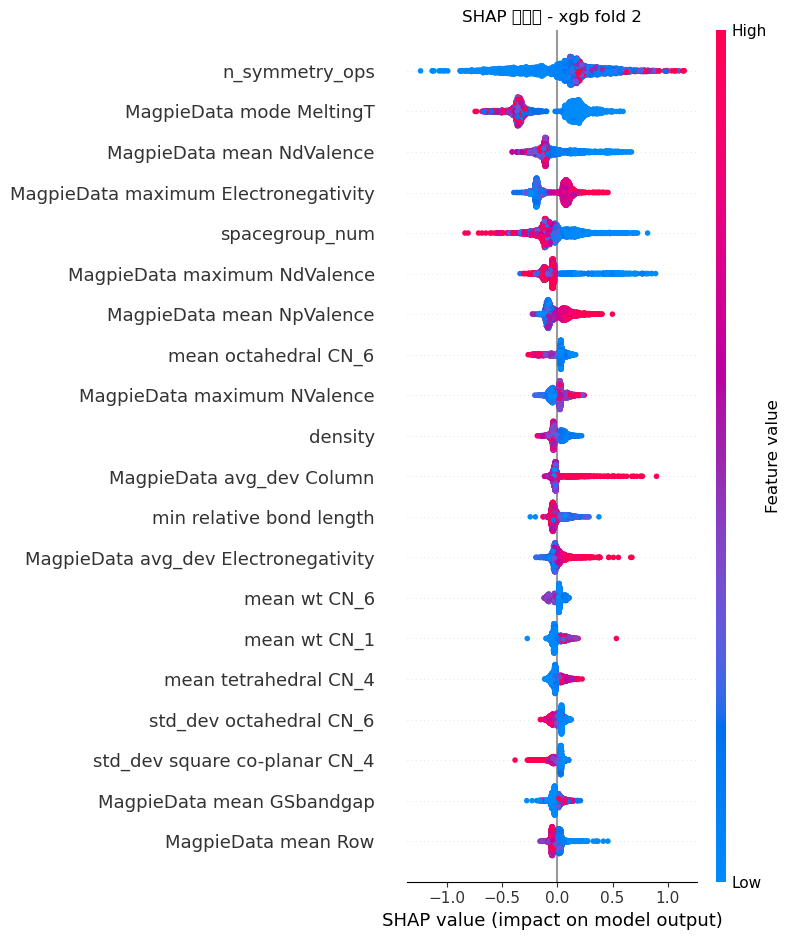

/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 37325 (\N{CJK UNIFIED IDEOGRAPH-91CD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 35201 (\N{CJK UNIFIED IDEOGRAPH-8981}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4

  → SHAP 蜂群图已保存: ../matbench_outputs_v2_seed202/shap_beeswarm_xgb_fold_2.png


~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 37325 (\N{CJK UNIFIED IDEOGRAPH-91CD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 35201 (\N{CJK UNIFIED IDEOGRAPH-8981}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: G

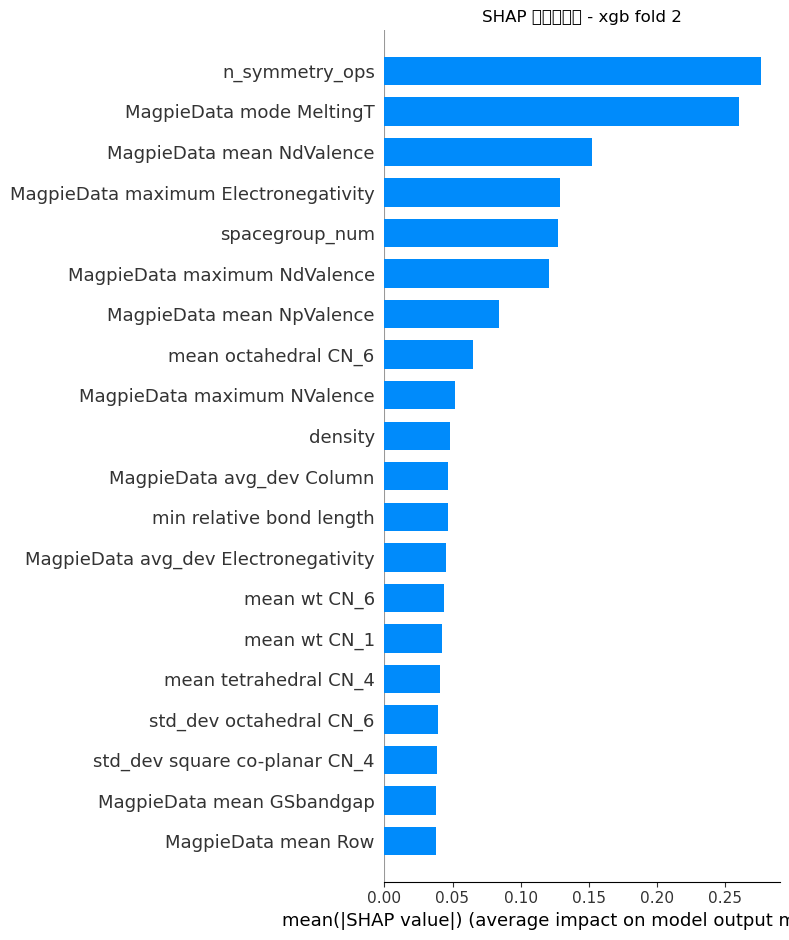

  → SHAP 重要性图已保存: ../matbench_outputs_v2_seed202/shap_importance_xgb_fold_2.png

  [特征重要性] Fold 3...


/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 37325 (\N{CJK UNIFIED IDEOGRAPH-91CD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 35201 (\N{CJK UNIFIED IDEOGRAPH-8981}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4

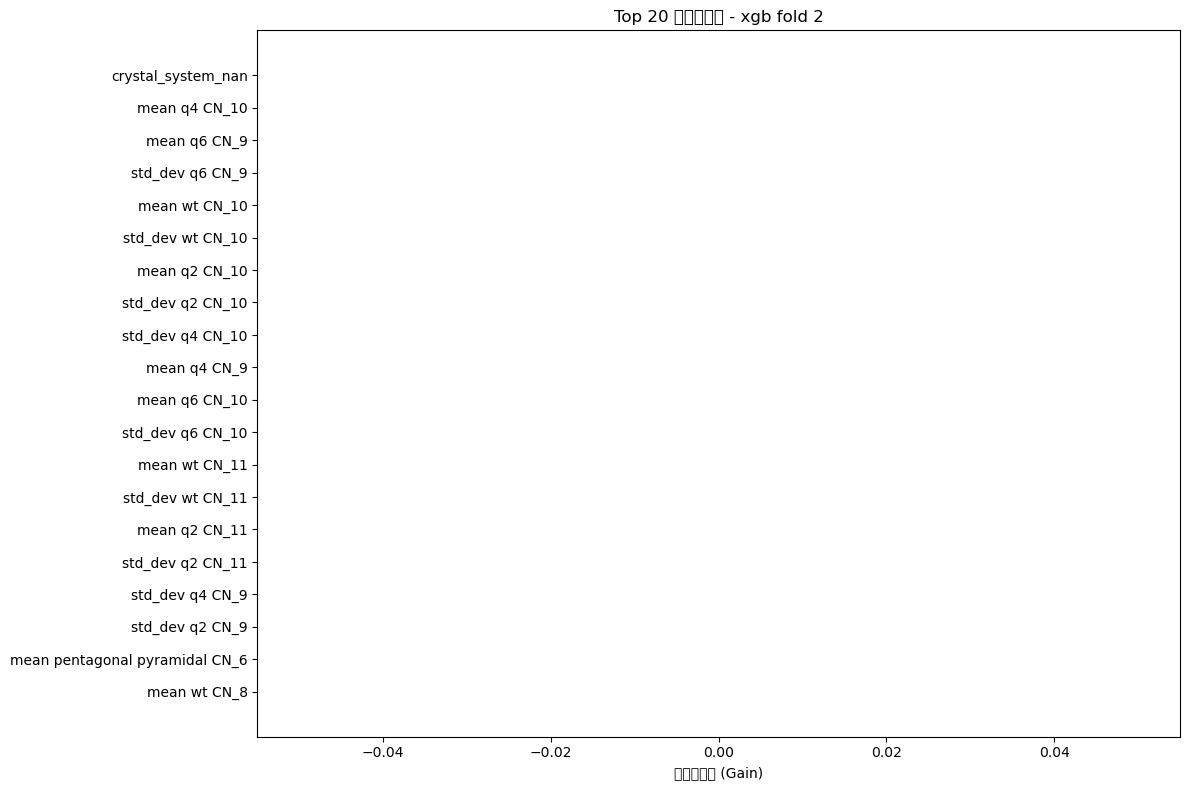

  → 特征重要性图已保存: ../matbench_outputs_v2_seed202/feature_importance_xgb_fold_2.png

  → 预测结果已保存: ../matbench_outputs_v2_seed202/predictions_xgb/pred_fold_2.npy
2026-10-08 02:44:45 INFO     Recorded fold matbench_mp_gap-2 successfully.
  → 已提交 fold 2 给 matbench

[xgb] Fold 4/5
  训练集: 84891 条，测试集: 21222 条
  ✅ GNN 数据已存在，跳过: fold_3

  提取训练集特征...

  [特征提取] fold_3_train


~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/featurizers/composition/element.py:216: UserWarning: BandCenter(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by th

  [1/2] 结构特征...
    ✅ 缓存命中: fold_3_train_DensityFeatures.pkl
    ✅ 缓存命中: fold_3_train_GlobalSymmetryFeatures.pkl
    ✅ 缓存命中: fold_3_train_StructuralHeterogeneity.pkl
    ✅ 缓存命中: fold_3_train_ChemicalOrdering.pkl
    ✅ 缓存命中: fold_3_train_Dimensionality.pkl
    ✅ 缓存命中: fold_3_train_SiteStatsFingerprint.pkl
  [2/2] 化学式特征...
    ✅ 缓存命中: fold_3_train_ElementProperty.pkl
    ✅ 缓存命中: fold_3_train_BandCenter.pkl
  ⚠️ 发现非数值特征列，将进行 one-hot 编码: ['crystal_system']
  ✅ fold_3_train 特征提取完成，总特征数: 283

  提取测试集特征...

  [特征提取] fold_3_test


~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/featurizers/composition/element.py:216: UserWarning: BandCenter(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by th

  [1/2] 结构特征...
    ✅ 缓存命中: fold_3_test_DensityFeatures.pkl
    ✅ 缓存命中: fold_3_test_GlobalSymmetryFeatures.pkl
    ✅ 缓存命中: fold_3_test_StructuralHeterogeneity.pkl
    ✅ 缓存命中: fold_3_test_ChemicalOrdering.pkl
    ✅ 缓存命中: fold_3_test_Dimensionality.pkl
    ✅ 缓存命中: fold_3_test_SiteStatsFingerprint.pkl
  [2/2] 化学式特征...
    ✅ 缓存命中: fold_3_test_ElementProperty.pkl
    ✅ 缓存命中: fold_3_test_BandCenter.pkl
  ⚠️ 发现非数值特征列，将进行 one-hot 编码: ['crystal_system']
  ✅ fold_3_test 特征提取完成，总特征数: 283
  [XGBoost Fold 4] 开始训练...
[0]	validation-mae:1.30563
[50]	validation-mae:0.71328
[100]	validation-mae:0.55021
[150]	validation-mae:0.49647
[200]	validation-mae:0.46714
[250]	validation-mae:0.44797
[300]	validation-mae:0.43532
[350]	validation-mae:0.42576
[400]	validation-mae:0.41704
[450]	validation-mae:0.41017
[500]	validation-mae:0.40409
[550]	validation-mae:0.39905
[600]	validation-mae:0.39379
[650]	validation-mae:0.38928
[700]	validation-mae:0.38520
[750]	validation-mae:0.38152
[800]	validation-mae:0.37759
[

/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 35757 (\N{CJK UNIFIED IDEOGRAPH-8BAD}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 32451 (\N{CJK UNIFIED IDEOGRAPH-7EC3}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.

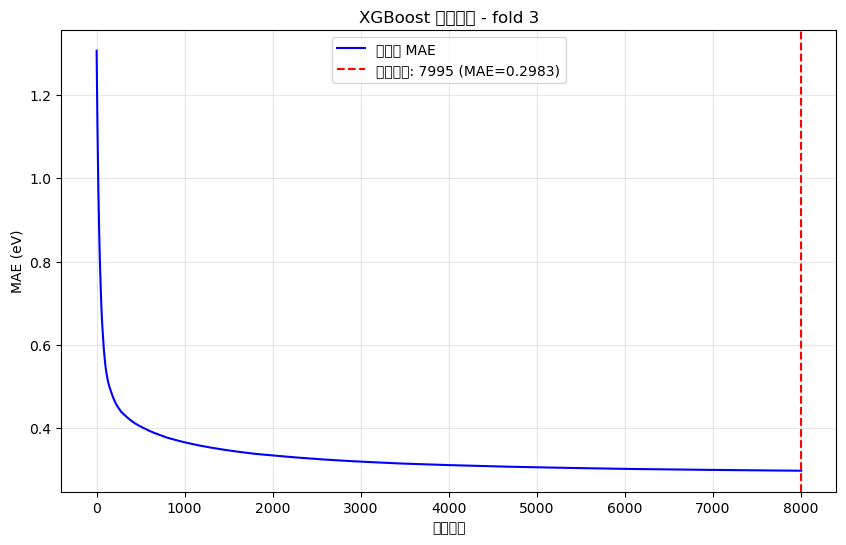

  → 训练曲线已保存: ../matbench_outputs_v2_seed202/xgb_mae_curve_fold_3.png

  [SHAP 分析] Fold 4...


/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:18: UserWarning: Glyph 34562 (\N{CJK UNIFIED IDEOGRAPH-8702}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:18: UserWarning: Glyph 32676 (\N{CJK UNIFIED IDEOGRAPH-7FA4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:18: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:20: UserWarning: Glyph 34562 (\N{CJK UNIFIED IDEOGRAPH-8702}) missing from font(s) DejaVu Sans.
  plt.savefig(beeswarm_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:20: UserWarning: Glyph 32676 (\N{CJK UNIFIED IDEOGRAPH-7FA4}) missing from font(s) DejaVu Sans.
  p

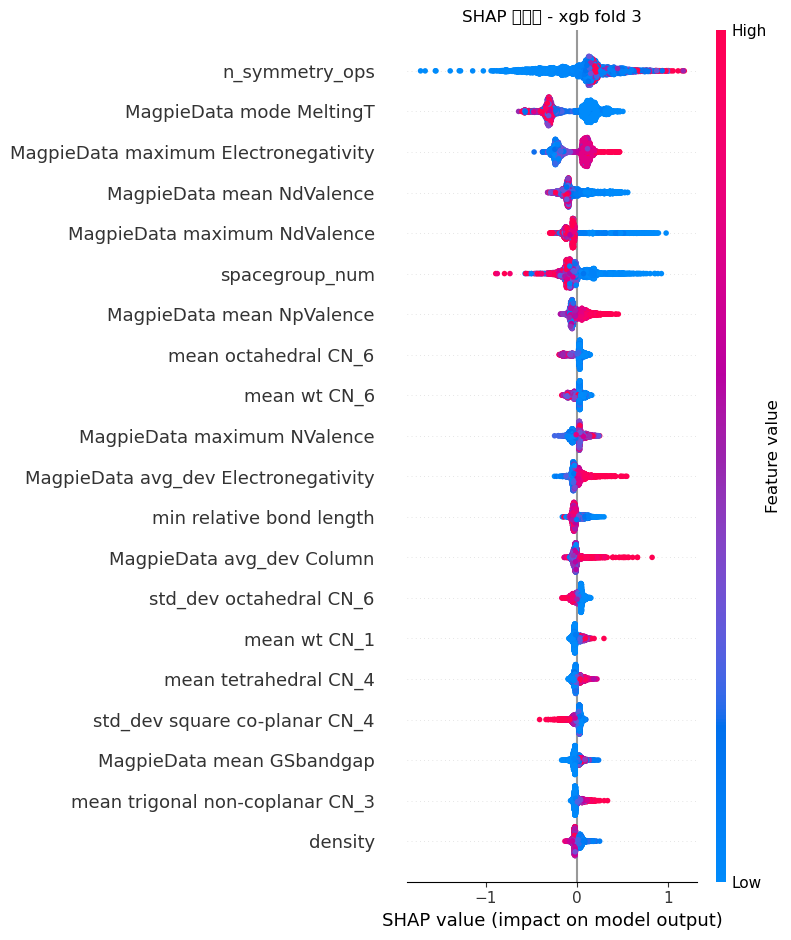

/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 37325 (\N{CJK UNIFIED IDEOGRAPH-91CD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 35201 (\N{CJK UNIFIED IDEOGRAPH-8981}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4

  → SHAP 蜂群图已保存: ../matbench_outputs_v2_seed202/shap_beeswarm_xgb_fold_3.png


~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 37325 (\N{CJK UNIFIED IDEOGRAPH-91CD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 35201 (\N{CJK UNIFIED IDEOGRAPH-8981}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: G

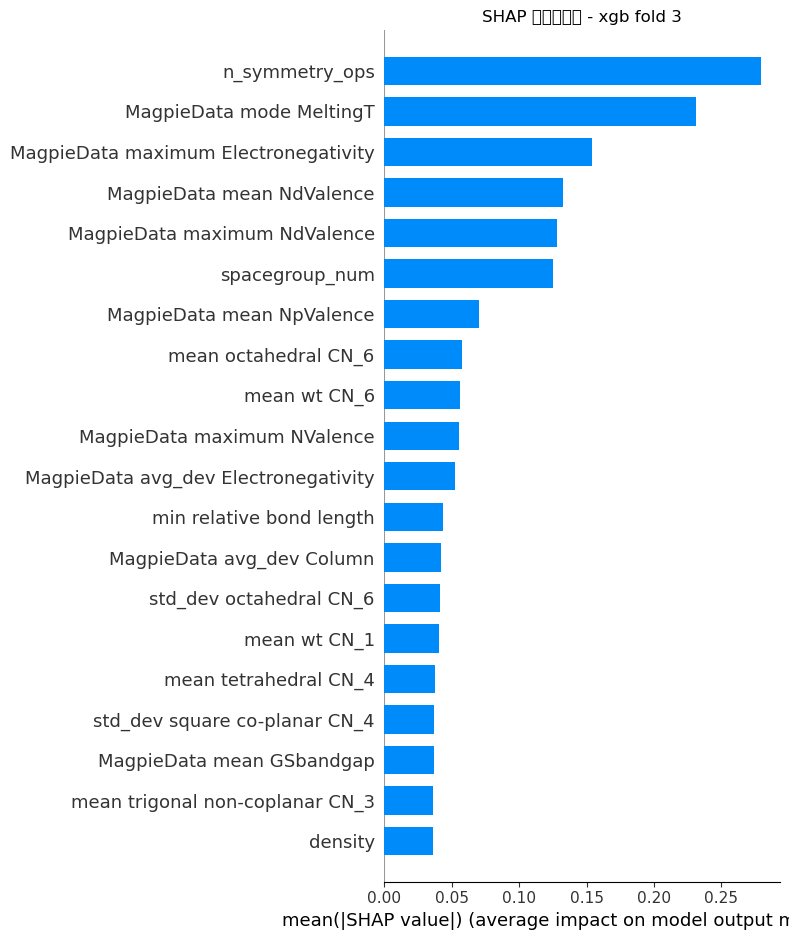

  → SHAP 重要性图已保存: ../matbench_outputs_v2_seed202/shap_importance_xgb_fold_3.png

  [特征重要性] Fold 4...


/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 37325 (\N{CJK UNIFIED IDEOGRAPH-91CD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 35201 (\N{CJK UNIFIED IDEOGRAPH-8981}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4

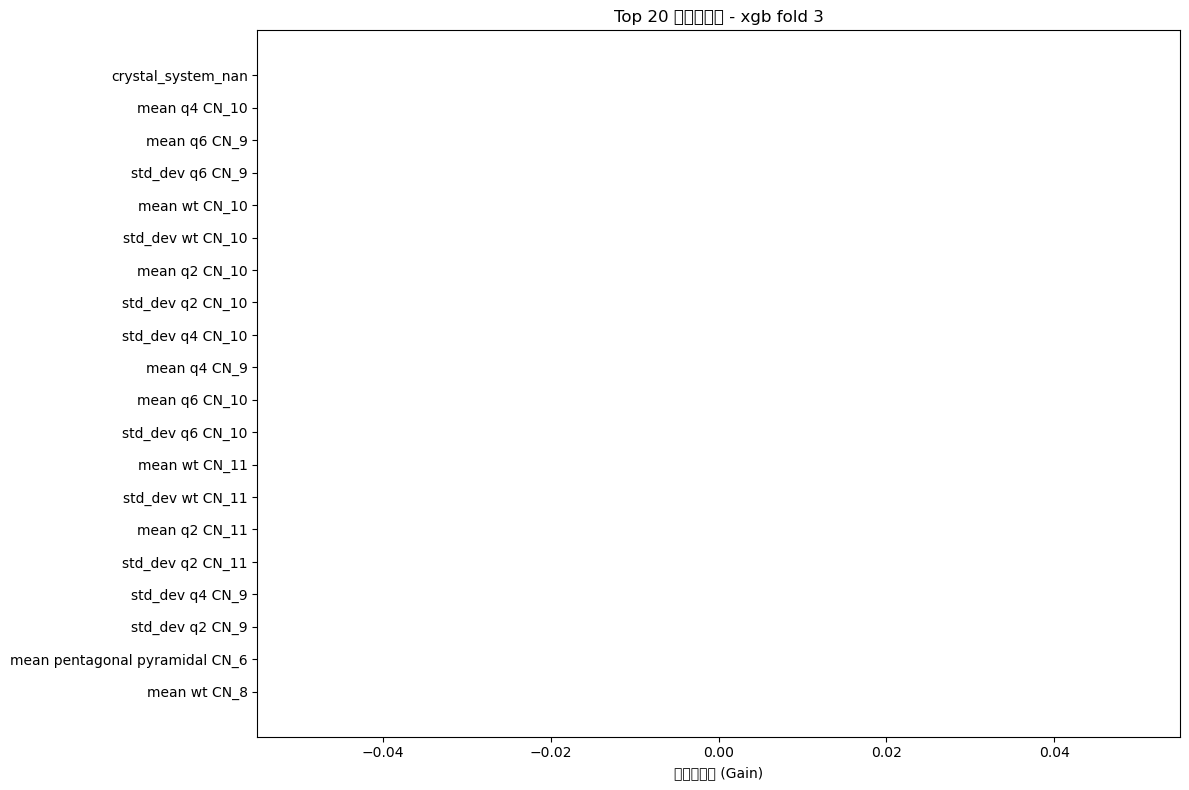

  → 特征重要性图已保存: ../matbench_outputs_v2_seed202/feature_importance_xgb_fold_3.png

  → 预测结果已保存: ../matbench_outputs_v2_seed202/predictions_xgb/pred_fold_3.npy
2026-10-08 02:46:37 INFO     Recorded fold matbench_mp_gap-3 successfully.
  → 已提交 fold 3 给 matbench

[xgb] Fold 5/5
  训练集: 84891 条，测试集: 21222 条
  ✅ GNN 数据已存在，跳过: fold_4

  提取训练集特征...

  [特征提取] fold_4_train


~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/featurizers/composition/element.py:216: UserWarning: BandCenter(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by th

  [1/2] 结构特征...
    ✅ 缓存命中: fold_4_train_DensityFeatures.pkl
    ✅ 缓存命中: fold_4_train_GlobalSymmetryFeatures.pkl
    ✅ 缓存命中: fold_4_train_StructuralHeterogeneity.pkl
    ✅ 缓存命中: fold_4_train_ChemicalOrdering.pkl
    ✅ 缓存命中: fold_4_train_Dimensionality.pkl
    ✅ 缓存命中: fold_4_train_SiteStatsFingerprint.pkl
  [2/2] 化学式特征...
    ✅ 缓存命中: fold_4_train_ElementProperty.pkl
    ✅ 缓存命中: fold_4_train_BandCenter.pkl
  ⚠️ 发现非数值特征列，将进行 one-hot 编码: ['crystal_system']
  ✅ fold_4_train 特征提取完成，总特征数: 283

  提取测试集特征...

  [特征提取] fold_4_test


~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/matminer/featurizers/composition/element.py:216: UserWarning: BandCenter(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by th

  [1/2] 结构特征...
    ✅ 缓存命中: fold_4_test_DensityFeatures.pkl
    ✅ 缓存命中: fold_4_test_GlobalSymmetryFeatures.pkl
    ✅ 缓存命中: fold_4_test_StructuralHeterogeneity.pkl
    ✅ 缓存命中: fold_4_test_ChemicalOrdering.pkl
    ✅ 缓存命中: fold_4_test_Dimensionality.pkl
    ✅ 缓存命中: fold_4_test_SiteStatsFingerprint.pkl
  [2/2] 化学式特征...
    ✅ 缓存命中: fold_4_test_ElementProperty.pkl
    ✅ 缓存命中: fold_4_test_BandCenter.pkl
  ⚠️ 发现非数值特征列，将进行 one-hot 编码: ['crystal_system']
  ✅ fold_4_test 特征提取完成，总特征数: 283
  [XGBoost Fold 5] 开始训练...
[0]	validation-mae:1.30910
[50]	validation-mae:0.71406
[100]	validation-mae:0.54977
[150]	validation-mae:0.49249
[200]	validation-mae:0.46344
[250]	validation-mae:0.44468
[300]	validation-mae:0.42947
[350]	validation-mae:0.41873
[400]	validation-mae:0.41065
[450]	validation-mae:0.40269
[500]	validation-mae:0.39686
[550]	validation-mae:0.39163
[600]	validation-mae:0.38683
[650]	validation-mae:0.38206
[700]	validation-mae:0.37830
[750]	validation-mae:0.37454
[800]	validation-mae:0.37095
[

/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 35757 (\N{CJK UNIFIED IDEOGRAPH-8BAD}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 32451 (\N{CJK UNIFIED IDEOGRAPH-7EC3}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.py:71: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  plt.savefig(curve_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/3302453100.

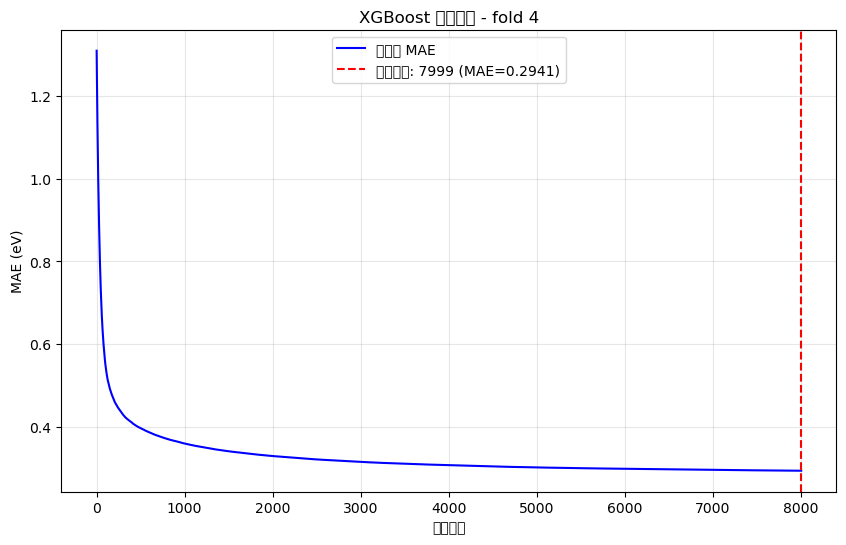

  → 训练曲线已保存: ../matbench_outputs_v2_seed202/xgb_mae_curve_fold_4.png

  [SHAP 分析] Fold 5...


/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:18: UserWarning: Glyph 34562 (\N{CJK UNIFIED IDEOGRAPH-8702}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:18: UserWarning: Glyph 32676 (\N{CJK UNIFIED IDEOGRAPH-7FA4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:18: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:20: UserWarning: Glyph 34562 (\N{CJK UNIFIED IDEOGRAPH-8702}) missing from font(s) DejaVu Sans.
  plt.savefig(beeswarm_path, dpi=150, bbox_inches='tight')
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:20: UserWarning: Glyph 32676 (\N{CJK UNIFIED IDEOGRAPH-7FA4}) missing from font(s) DejaVu Sans.
  p

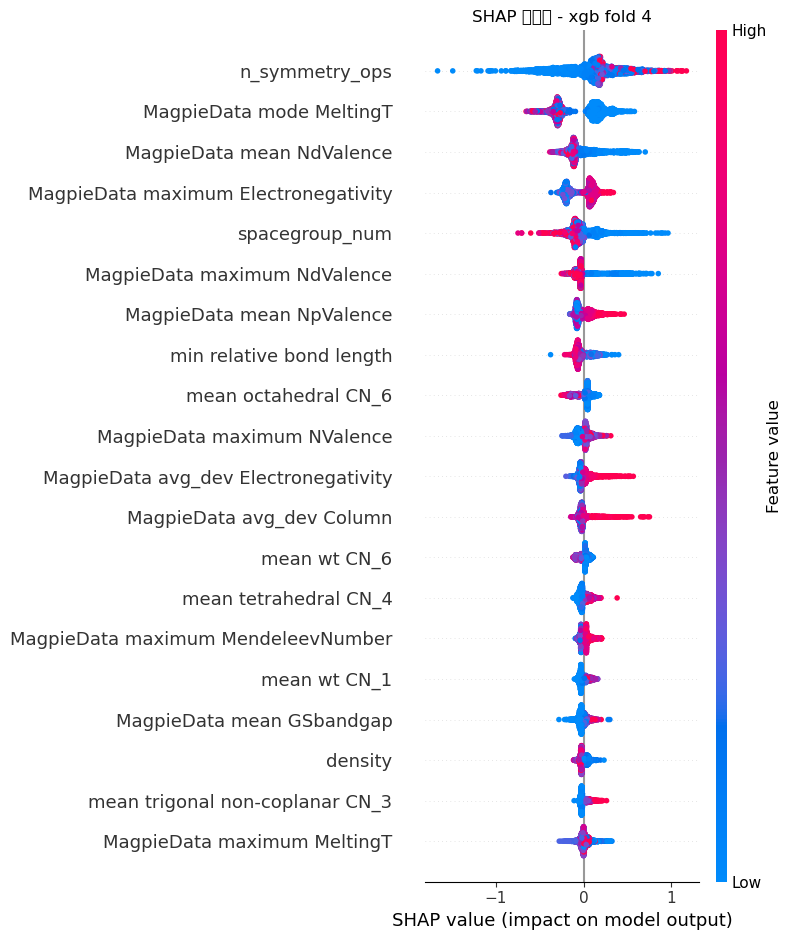

/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 37325 (\N{CJK UNIFIED IDEOGRAPH-91CD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 35201 (\N{CJK UNIFIED IDEOGRAPH-8981}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:29: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4

  → SHAP 蜂群图已保存: ../matbench_outputs_v2_seed202/shap_beeswarm_xgb_fold_4.png


~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 37325 (\N{CJK UNIFIED IDEOGRAPH-91CD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 35201 (\N{CJK UNIFIED IDEOGRAPH-8981}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
~/miniforge3/envs/matbench3.9/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: G

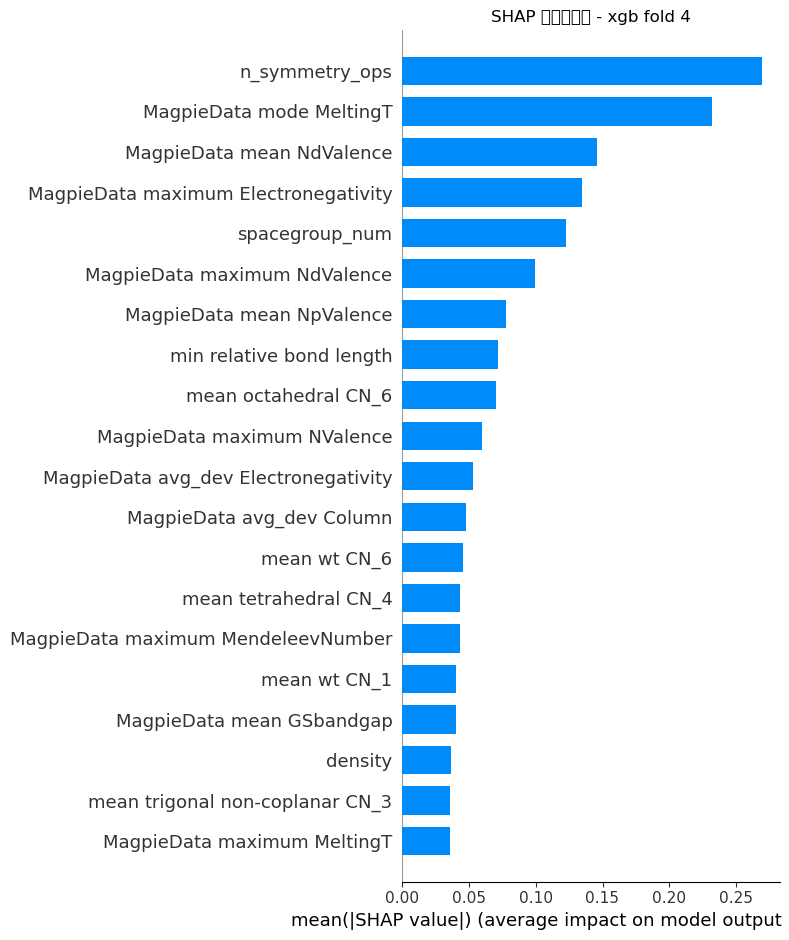

  → SHAP 重要性图已保存: ../matbench_outputs_v2_seed202/shap_importance_xgb_fold_4.png

  [特征重要性] Fold 5...


/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 37325 (\N{CJK UNIFIED IDEOGRAPH-91CD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 35201 (\N{CJK UNIFIED IDEOGRAPH-8981}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4qppn2fb8h1c8fzflvkhr0000gn/T/ipykernel_27032/2071643421.py:57: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9j/x4s4

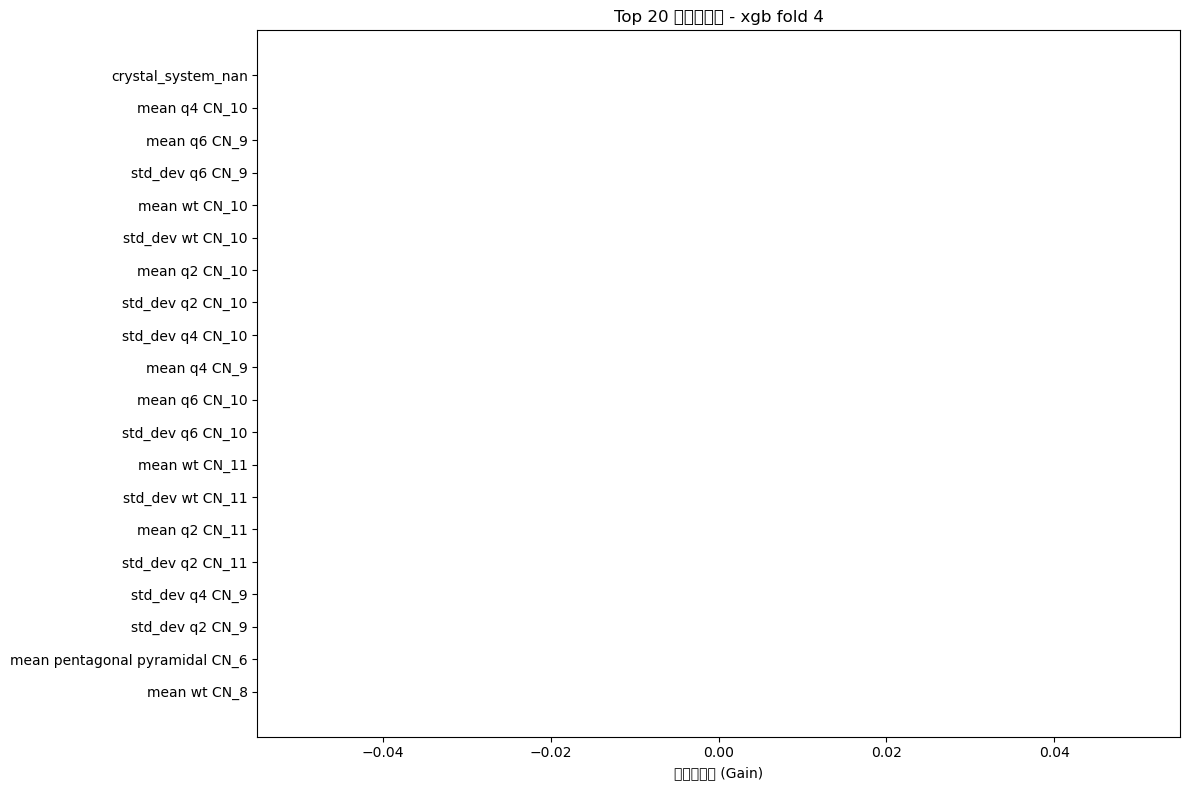

  → 特征重要性图已保存: ../matbench_outputs_v2_seed202/feature_importance_xgb_fold_4.png

  → 预测结果已保存: ../matbench_outputs_v2_seed202/predictions_xgb/pred_fold_4.npy
2026-10-08 02:48:26 INFO     Recorded fold matbench_mp_gap-4 successfully.
  → 已提交 fold 4 给 matbench

✅ 官方分数: {'mae': {'mean': np.float64(0.2860211227259308), 'max': np.float64(0.2900754850823778), 'min': np.float64(0.28288147138044323), 'std': np.float64(0.0024190499008969954)}, 'rmse': {'mean': np.float64(0.5000196512560914), 'max': np.float64(0.5111600224826334), 'min': np.float64(0.49429580754054564), 'std': np.float64(0.006476639716938405)}, 'mape': {'mean': np.float64(5.634315362844236), 'max': np.float64(9.196294697049943), 'min': np.float64(2.8696880108373115), 'std': np.float64(2.242820568853872)}, 'max_error': {'mean': np.float64(5.053171634674072), 'max': np.float64(5.7270827293396), 'min': np.float64(4.663212776184082), 'std': np.float64(0.3793448113785229)}}
✅ 分数已保存: ../matbench_outputs_v2_seed202/scores_xgb.txt

✅ 全部完

In [9]:
# ==================== Cell 9：运行！ ====================
# 上面所有 cell 都是「准备工具」，这里才是「开始干活」
#
# 跑之前确认：
#   ✅ Cell 1~8 都已经跑过了
#   ✅ MODELS_TO_RUN 是你想跑的模型
#   ✅ TEST_MODE=True（先测试）或 False（正式跑）

all_scores = {}
for model_name in MODELS_TO_RUN:
	print(f'\n{"="*60}')
	print(f'=== 开始跑模型: {model_name} ===')
	print(f'{"="*60}')
	all_scores[model_name] = run_one_model(model_name)

print(f'\n{"="*60}')
print('✅ 全部完成！分数汇总:')
for k, v in all_scores.items():
	print(f'  {k}: {v}')
print('='*60)

In [10]:
import numpy as np
from pathlib import Path

NEW    = Path("../matbench_outputs_v2_run0709_replay").resolve()
FROZEN = Path("../matbench_outputs_v2_run0709").resolve()
MODEL  = "xgb"
EXPECTED_N = 106_113

print("本次输出：", NEW)
print("冻结版本：", FROZEN)

all_ok, n_total, n_neg = True, 0, 0
p_new, p_old = NEW / f"predictions_{MODEL}", FROZEN / f"predictions_{MODEL}"

for k in range(5):
    new_clip = np.load(p_new / f"pred_fold_{k}.npy", allow_pickle=False)
    old_clip = np.load(p_old / f"pred_fold_{k}.npy", allow_pickle=False)
    new_raw  = np.load(p_new / f"pred_raw_fold_{k}.npy", allow_pickle=False)

    arrays = (new_clip, old_clip, new_raw)
    if not (all(a.ndim == 1 and a.size > 0 for a in arrays)
            and new_clip.shape == old_clip.shape == new_raw.shape):
        all_ok = False
        print(f"fold {k}: ❌ shape 不符合预期：{[a.shape for a in arrays]}")
        continue
    if not all(np.isfinite(a).all() for a in arrays):
        all_ok = False
        print(f"fold {k}: ❌ 预测中存在 NaN 或 Inf")
        continue

    clip_ok  = np.array_equal(new_clip, old_clip)
    n_diff   = int(np.count_nonzero(new_clip != old_clip))
    max_diff = float(np.max(np.abs(new_clip.astype(np.float64) - old_clip.astype(np.float64))))
    raw_ok   = np.array_equal(np.maximum(new_raw, 0), new_clip)
    ok  = clip_ok and raw_ok
    msg = (f"fold {k}: n={new_clip.size}, 不一致条数={n_diff}, "
           f"max_diff={max_diff:.12g}, raw→clip一致={raw_ok}")

    # 可选: SHAP 值对比 (两边都有才比)
    s_new = NEW    / f"shap_values_{MODEL}_fold_{k}.npy"
    s_old = FROZEN / f"shap_values_{MODEL}_fold_{k}.npy"
    if s_new.exists() and s_old.exists():
        a, b = np.load(s_new, allow_pickle=False), np.load(s_old, allow_pickle=False)
        shap_ok = a.shape == b.shape and np.array_equal(a, b)
        ok = ok and shap_ok
        msg += f"\n  SHAP 一致={shap_ok} (shape {a.shape} vs {b.shape})"
    else:
        msg += "\n  SHAP: 跳过 (有一边缺文件)"

    all_ok = all_ok and ok
    n_total += new_raw.size
    n_neg   += int(np.count_nonzero(new_raw < 0))
    print(msg, "✅" if ok else "❌")

total_ok = n_total == EXPECTED_N
all_ok = all_ok and total_ok
print(f"\n已核对样本数 {n_total}，预期 {EXPECTED_N} {'✅' if total_ok else '❌'}")
if n_total:
    print(f"raw 负值数量 {n_neg}，占比 {n_neg / n_total:.4%}")
print("上述检查全部通过 ✅" if all_ok else "存在需要检查的差异 ❌")

本次输出： ~/material_projects_structure_release_snapshot_v5/matbench_outputs_v2_run0709_replay
冻结版本： ~/material_projects_structure_release_snapshot_v5/matbench_outputs_v2_run0709
fold 0: n=21223, 不一致条数=0, max_diff=0, raw→clip一致=True
  SHAP 一致=True (shape (3000, 283) vs (3000, 283)) ✅
fold 1: n=21223, 不一致条数=0, max_diff=0, raw→clip一致=True
  SHAP 一致=True (shape (3000, 283) vs (3000, 283)) ✅
fold 2: n=21223, 不一致条数=0, max_diff=0, raw→clip一致=True
  SHAP 一致=True (shape (3000, 283) vs (3000, 283)) ✅
fold 3: n=21222, 不一致条数=0, max_diff=0, raw→clip一致=True
  SHAP 一致=True (shape (3000, 283) vs (3000, 283)) ✅
fold 4: n=21222, 不一致条数=0, max_diff=0, raw→clip一致=True
  SHAP 一致=True (shape (3000, 283) vs (3000, 283)) ✅

已核对样本数 106113，预期 106113 ✅
raw 负值数量 19163，占比 18.0591%
上述检查全部通过 ✅


In [11]:
import numpy as np
from pathlib import Path
from matbench.bench import MatbenchBenchmark

NEW = Path("../matbench_outputs_v2_run0709_replay").resolve()
p_new = NEW / "predictions_xgb"

mb = MatbenchBenchmark(autoload=False)          # 只加载 mp_gap, 很快
task = next(t for t in mb.tasks if t.dataset_name == "matbench_mp_gap")
task.load()
target_col = task.metadata["target"]

tot_neg = tot_neg_zero = tot_zero = 0
for k, fold in enumerate(task.folds):
    test_df = task.get_test_data(fold, as_type="df", include_target=True)
    test_df = test_df.rename(columns=lambda x: x.strip())
    y_true = test_df[target_col].to_numpy(dtype=float)
    raw = np.load(p_new / f"pred_raw_fold_{fold}.npy", allow_pickle=False)
    assert len(raw) == len(y_true), f"fold {fold} 长度不匹配"

    neg  = raw < 0
    zero = y_true == 0
    n_neg, n_neg_zero, n_zero = int(neg.sum()), int((neg & zero).sum()), int(zero.sum())
    tot_neg += n_neg; tot_neg_zero += n_neg_zero; tot_zero += n_zero
    print(f"fold {fold}: 负值 {n_neg}，其中真值=0 的 {n_neg_zero}，"
          f"真值≠0 的 {n_neg - n_neg_zero}")

print(f"\n负值总数: {tot_neg}")
print(f"落在零带隙样本上: {tot_neg_zero}  ({tot_neg_zero/tot_neg:.2%} 的负值)")
print(f"落在非零带隙样本上: {tot_neg - tot_neg_zero}")
print(f"零带隙样本总数: {tot_zero}")

2026-10-08 02:48:29 INFO     Initialized benchmark 'matbench_v0.1' with 13 tasks: 
['matbench_dielectric',
 'matbench_expt_gap',
 'matbench_expt_is_metal',
 'matbench_glass',
 'matbench_jdft2d',
 'matbench_log_gvrh',
 'matbench_log_kvrh',
 'matbench_mp_e_form',
 'matbench_mp_gap',
 'matbench_mp_is_metal',
 'matbench_perovskites',
 'matbench_phonons',
 'matbench_steels']
2026-10-08 02:48:31 INFO     Loading dataset 'matbench_mp_gap'...
2026-10-08 02:49:35 INFO     Dataset 'matbench_mp_gap loaded.
fold 0: 负值 3802，其中真值=0 的 3539，真值≠0 的 263
fold 1: 负值 3850，其中真值=0 的 3603，真值≠0 的 247
fold 2: 负值 3860，其中真值=0 的 3583，真值≠0 的 277
fold 3: 负值 3851，其中真值=0 的 3610，真值≠0 的 241
fold 4: 负值 3800，其中真值=0 的 3547，真值≠0 的 253

负值总数: 19163
落在零带隙样本上: 17882  (93.32% 的负值)
落在非零带隙样本上: 1281
零带隙样本总数: 46151


In [12]:
# [replay] 历史遗留 OOF cell, 已注释, 后续分析未使用
# # ==================== OOF: RF vs XGB 对比可视化 ====================
# # Optional fold-0 inner-OOF diagnostic; not used for manuscript results.
#
# RUN_OOF_COMPARISON = False
# OOF_MODELS_TO_RUN = ["rf", "xgb"]
#
# def run_oof_comparison_on_fold0():
# 	"""
# 	在 matbench fold_0 的训练集上做标准 OOF。
# 	目的：
# 		1. 对比 RF 和 XGB 在训练集上的泛化表现
# 		2. 画 true vs predicted 图
# 		3. 导出误差最大的样本
#
# 	注意：
# 		这里不是 matbench 官方 test 分数。
# 		这里只是在 fold_0 的 train_and_val_data 内部再做 KFold。
# 	"""
# 	print("\n" + "="*60)
# 	print("开始 OOF 对比: RF vs XGB")
# 	print("="*60)
#
# 	# 重新加载 task，避免和前面 record 状态混在一起
# 	mb_oof = MatbenchBenchmark(autoload=False)
# 	task_oof = next(t for t in mb_oof.tasks if t.dataset_name == TASK_NAME)
# 	task_oof.load()
#
# 	# 使用 matbench fold_0 的训练集
# 	df = task_oof.get_train_and_val_data(0, as_type="df")
# 	df = df.rename(columns=lambda x: x.strip())
#
# 	if TEST_MODE:
# 		print(f"⚠️ TEST_MODE=True：OOF 只取前 {TEST_N} 条，图只能测试流程，不代表真实性能")
# 		df = df.iloc[:TEST_N].copy()
#
# 	mbids = np.array([str(x) for x in df.index], dtype=object)
# 	y = df[target_col].to_numpy(dtype=float)
# 	X_raw = df["structure"].tolist()
#
# 	print(f"OOF 样本数: {len(y)}")
#
# 	# 关键改动：
# 	# 不再读取旧的 FEATURES_CACHE，而是调用 extract_features。
# 	# extract_features 内部会按 featurizer 分别缓存。
# 	X_df = extract_features(X_raw, split_name="fold_0_train")
# 	# X_df 保留 NaN，填充在每个 OOF fold 内用训练子集统计量执行
# 	X = X_df
#
# 	if len(X) != len(y):
# 		raise ValueError(f"特征和标签数量不匹配: X={len(X)}, y={len(y)}")
#
# 	rf_params = {
# 		"n_estimators": 300,
# 		"random_state": SEED,
# 		"n_jobs": N_JOBS,
# 	}
#
# 	xgb_params = {
# 		"objective": "reg:squarederror",
# 		"eval_metric": "mae",
# 		"tree_method": "hist",
# 		"seed": SEED,
# 		"eta": 0.03,
# 		"max_depth": 6,
# 		"min_child_weight": 5,
# 		"subsample": 0.8,
# 		"colsample_bytree": 0.8,
# 		"lambda": 1.0,
# 		"alpha": 1e-3,
# 	}
#
# 	kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
# 	oof_dict = {
# 		model: np.full(len(y), np.nan)
# 		for model in OOF_MODELS_TO_RUN
# 	}
#
# 	for inner_fold, (tr_idx, va_idx) in enumerate(kf.split(X)):
# 		print(f"\nOOF inner fold {inner_fold+1}/{N_SPLITS}")
#
# 		X_tr, y_tr = X.iloc[tr_idx], y[tr_idx]
# 		X_va, y_va = X.iloc[va_idx], y[va_idx]
#
# 		# 填充: 只用本 OOF fold 训练子集的均值
# 		col_means = X_tr.mean(numeric_only=True)
# 		X_tr = X_tr.fillna(col_means).fillna(0).to_numpy()
# 		X_va = X_va.fillna(col_means).fillna(0).to_numpy()
#
# 		# ---------- RF ----------
# 		if "rf" in OOF_MODELS_TO_RUN:
# 			rf = RandomForestRegressor(**rf_params)
# 			rf.fit(X_tr, y_tr)
# 			oof_dict["rf"][va_idx] = np.maximum(rf.predict(X_va), 0)  # clip
#
# 			mae_rf = mean_absolute_error(y_va, oof_dict["rf"][va_idx])
# 			print(f"[RF]  Fold MAE: {mae_rf:.4f} eV")
#
# 		# ---------- XGB ----------
# 		if "xgb" in OOF_MODELS_TO_RUN:
# 			# XGBoost 内部再切一小块做 early stopping
# 			inner_tr_idx, inner_va_idx = train_test_split(
# 				np.arange(len(X_tr)),
# 				test_size=0.1,
# 				random_state=SEED,
# 				shuffle=True,
# 			)
#
# 			dtr = xgb.DMatrix(X_tr[inner_tr_idx], label=y_tr[inner_tr_idx])
# 			dval = xgb.DMatrix(X_tr[inner_va_idx], label=y_tr[inner_va_idx])
# 			douter = xgb.DMatrix(X_va)
#
# 			booster = xgb.train(
# 				params=xgb_params,
# 				dtrain=dtr,
# 				num_boost_round=8000 if not TEST_MODE else 500,
# 				evals=[(dval, "valid")],
# 				early_stopping_rounds=200 if not TEST_MODE else 50,
# 				verbose_eval=False,
# 			)
#
# 			best_it = booster.best_iteration
#
# 			try:
# 				pred = booster.predict(douter, iteration_range=(0, best_it + 1))
# 			except TypeError:
# 				pred = booster.predict(douter, ntree_limit=best_it + 1)
#
# 			oof_dict["xgb"][va_idx] = np.maximum(pred, 0)  # clip
#
# 			mae_xgb = mean_absolute_error(y_va, oof_dict["xgb"][va_idx])
# 			print(f"[XGB] Fold MAE: {mae_xgb:.4f} eV, best_it={best_it}")
#
# 	# 保存 OOF 结果
# 	for model in OOF_MODELS_TO_RUN:
# 		if np.isnan(oof_dict[model]).any():
# 			raise ValueError(f"{model} 的 OOF 预测里还有 NaN，说明有些样本没有被预测到")
#
# 		np.savez(
# 			OUT_DIR / f"oof_std_{model}{'_testmode' if TEST_MODE else ''}.npz",
# 			mbid=mbids,
# 			y_true=y,
# 			y_pred=oof_dict[model],
# 		)
# 		print(f"✅ {model} OOF 预测已保存")
#
# 	# 画图函数
# 	def plot_oof(model_name, y_true, y_pred):
# 		mae = mean_absolute_error(y_true, y_pred)
# 		rmse = np.sqrt(mean_squared_error(y_true, y_pred))
# 		r2 = r2_score(y_true, y_pred)
#
# 		plt.figure(figsize=(6, 6))
# 		plt.scatter(y_true, y_pred, alpha=0.35, s=10)
#
# 		mn = min(y_true.min(), y_pred.min())
# 		mx = max(y_true.max(), y_pred.max())
# 		plt.plot([mn, mx], [mn, mx], linestyle="--", label="Perfect Prediction")
#
# 		plt.xlabel("True Gap (eV)")
# 		plt.ylabel("Predicted Gap (eV)")
# 		plt.title(f"OOF Prediction vs True ({model_name})")
#
# 		plt.text(
# 			0.05,
# 			0.95,
# 			f"MAE={mae:.4f} eV\nRMSE={rmse:.4f} eV\nR²={r2:.4f}",
# 			transform=plt.gca().transAxes,
# 			va="top",
# 			bbox=dict(boxstyle="round", facecolor="white", alpha=0.85),
# 		)
#
# 		plt.tight_layout()
# 		fig_path = OUT_DIR / f"oof_pred_vs_true_{model_name}{'_testmode' if TEST_MODE else ''}.png"
# 		plt.savefig(fig_path, dpi=200)
# 		plt.close()
# 		print(f"✅ OOF 对比图保存: {fig_path}")
#
# 	# 导出 Top error
# 	def export_topk(model_name, mbids, y_true, y_pred, topk=TOPK):
# 		abs_err = np.abs(y_true - y_pred)
# 		idx = np.argsort(abs_err)[::-1][:topk]
#
# 		df_top = pd.DataFrame({
# 			"mp_id": mbids[idx],
# 			"true_gap_eV": y_true[idx],
# 			"pred_gap_eV": y_pred[idx],
# 			"abs_error_eV": abs_err[idx],
# 		})
#
# 		out_csv = OUT_DIR / f"abs_err_top{topk}_{model_name}{'_testmode' if TEST_MODE else ''}.csv"
# 		df_top.to_csv(out_csv, index=False)
# 		print(f"✅ Top{topk} 错误样本保存: {out_csv}")
# 		return df_top
#
# 	for model in OOF_MODELS_TO_RUN:
# 		plot_oof(model, y, oof_dict[model])
# 		export_topk(model, mbids, y, oof_dict[model])
#
# 	print("✅ OOF 对比完成")

In [13]:
# [replay] 历史遗留 OOF 调用, 已注释
# if RUN_OOF_COMPARISON:
#     run_oof_comparison_on_fold0()